# Roteiro 4 — Monitoramento de um detector de phishing em produção

**Cibersegurança Aplicada com IA · Insper 2026-2**

Dupla: **Antonio Almeida** e **Luka Figueiredo**

Cenário: a Atlas Logística usa um Random Forest (treinado nas semanas 1–6, limiar 0,30 escolhido nas semanas 7–8) que entrou em produção na semana 9 e nunca foi retreinado. Temos as semanas 9 a 40 de produção.

Regras seguidas em todo o notebook:
- limiar fixo de **0,30**;
- no início da semana *t* só se conhecem os rótulos verificados até a semana **t − 3**;
- todo modelo novo usa `RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5, random_state=7, n_jobs=-1)` com as 13 features na ordem do LEIA-ME;
- desvio-padrão amostral (`.std()` do pandas); médias de várias semanas = média das métricas semanais;
- funções `psi` e `PageHinkley` exatamente como na seção 5 do enunciado.

In [1]:
# pip install -q scikit-learn==1.9.1 pandas numpy scipy matplotlib joblib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("scikit-learn", sklearn.__version__)

DADOS = "dados/"   # conteúdo de R5_monitoramento_drift.zip
LIMIAR = 0.30
FEATURES = ["n_links", "link_divergente", "idade_dominio_dias", "spf_dkim_ok", "anexo_risco",
            "palavras_urgencia", "erros_ortografia", "pede_credencial", "pede_pagamento",
            "remetente_externo", "primeiro_contato", "tem_qr_code", "tamanho_kb"]

def novo_modelo():
    return RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5,
                                  random_state=7, n_jobs=-1)

def psi(ref, cur, bins=10, eps=1e-4):
    ref = np.asarray(ref, float)
    cur = np.asarray(cur, float)
    vals = np.unique(ref)
    if len(vals) <= bins:
        # feature binária ou com poucos valores: usa os próprios valores
        cats = np.union1d(vals, np.unique(cur))
        pr = np.array([(ref == v).mean() for v in cats])
        pc = np.array([(cur == v).mean() for v in cats])
    else:
        # faixas pelos decis da referência
        q = np.quantile(ref, np.linspace(0, 1, bins + 1))[1:-1]
        cortes = np.unique(q)
        k = len(cortes) + 1
        ir = np.searchsorted(cortes, ref, side="right")
        ic = np.searchsorted(cortes, cur, side="right")
        pr = np.bincount(ir, minlength=k) / len(ref)
        pc = np.bincount(ic, minlength=k) / len(cur)
    pr = np.clip(pr, eps, None)
    pc = np.clip(pc, eps, None)
    return float(np.sum((pc - pr) * np.log(pc / pr)))

class PageHinkley:
    '''Dispara quando a média do sinal (aqui, a taxa de erro) sobe.'''
    def __init__(self, delta=0.05, lamb=8.0):
        self.delta, self.lamb = delta, lamb
        self.n = 0; self.media = 0.0; self.m = 0.0; self.m_min = 0.0

    def atualizar(self, x):
        self.n += 1
        self.media += (x - self.media) / self.n
        self.m += x - self.media - self.delta
        self.m_min = min(self.m_min, self.m)
        return (self.m - self.m_min) > self.lamb

scikit-learn 1.9.1


---
## a) Linha de base e painel sem rótulos

### a.1 Carregar os arquivos

In [2]:
ref  = pd.read_csv(DADOS + "referencia.csv.gz")
prod = pd.read_csv(DADOS + "producao.csv.gz")
ouro = pd.read_csv(DADOS + "ouro.csv.gz")
modelo = joblib.load(DADOS + "modelo_producao.joblib")

for nome, d in [("referencia", ref), ("producao", prod), ("ouro", ouro)]:
    print(f"{nome:10s} {d.shape}  semanas {d.semana.min()}–{d.semana.max()}  "
          f"phishing = {d.rotulo.mean():.3f}")
print(modelo)

referencia (24166, 18)  semanas 1–8  phishing = 0.038
producao   (97326, 21)  semanas 9–40  phishing = 0.051
ouro       (2928, 16)  semanas 1–8  phishing = 0.317
RandomForestClassifier(max_depth=12, min_samples_leaf=5, n_jobs=-1,
                       random_state=7)


### a.2 Desempenho de base nas semanas 7 e 8 e conferência do score

In [3]:
val = ref[ref.semana.isin([7, 8])].copy()
val["score_rec"] = modelo.predict_proba(val[FEATURES].values)[:, 1].round(4)
val["pred"] = (val.score_rec >= LIMIAR).astype(int)

# conferência do score recalculado com a coluna gravada
dif = (val.score_rec - val.score).abs()
print(f"score recalculado x coluna score (sem. 7–8): diferença máxima = {dif.max():.4f}, "
      f"iguais = {(dif == 0).mean():.2%}, alerta igual = {(val.pred == val.alerta).mean():.2%}")

# a mesma conferência em toda a produção
s_prod = modelo.predict_proba(prod[FEATURES].values)[:, 1].round(4)
print(f"score recalculado x coluna score (produção): diferença máxima = "
      f"{np.abs(s_prod - prod.score).max():.4f}")

base = []
for s in [7, 8]:
    v = val[val.semana == s]
    base.append({"semana": s, "precisao": precision_score(v.rotulo, v.pred),
                 "recall": recall_score(v.rotulo, v.pred)})
base = pd.DataFrame(base).set_index("semana")
base.loc["média 7–8"] = base.mean()
PREC_BASE, REC_BASE = base.loc["média 7–8"]
base.round(4)

score recalculado x coluna score (sem. 7–8): diferença máxima = 0.0000, iguais = 100.00%, alerta igual = 100.00%
score recalculado x coluna score (produção): diferença máxima = 0.0000


,precisao,recall
semana,,
7,0.8829,0.9899
8,0.9421,0.9913
média 7–8,0.9125,0.9906


### a.3 Painel semanal sem rótulos

Quatro sinais que existem no mesmo dia: fração em quarentena (`alerta`), score médio, liberações (`feedback_usuario = -1`) e reportes (`feedback_usuario = +1`). A faixa normal é média ± 3 desvios amostrais das semanas 9 a 12.

In [4]:
painel = prod.groupby("semana").agg(
    emails=("id_email", "size"),
    quarentena=("alerta", "mean"),
    score_medio=("score", "mean"),
    liberacoes=("feedback_usuario", lambda f: (f == -1).sum()),
    reportes=("feedback_usuario", lambda f: (f == 1).sum()),
)
SERIES = ["quarentena", "score_medio", "liberacoes", "reportes"]

b = painel.loc[9:12, SERIES]
faixa = pd.DataFrame({"media": b.mean(), "desvio": b.std()})   # desvio amostral (ddof=1)
faixa["inf"] = faixa.media - 3 * faixa.desvio
faixa["sup"] = faixa.media + 3 * faixa.desvio
display(faixa.round(4))

fora = pd.DataFrame({c: np.select([painel[c] > faixa.loc[c, "sup"], painel[c] < faixa.loc[c, "inf"]],
                                  ["▲", "▼"], "") for c in SERIES}, index=painel.index)
painel_fmt = painel.copy()
painel_fmt["quarentena"] = painel_fmt.quarentena.round(4)
painel_fmt["score_medio"] = painel_fmt.score_medio.round(4)
painel_fmt.join(fora, rsuffix="_fora")

,media,desvio,inf,sup
quarentena,0.0420,0.0018,0.0366,0.0473
score_medio,0.0388,0.0022,0.0323,0.0453
liberacoes,8.5000,1.2910,4.6270,12.3730
reportes,6.5000,4.3589,-6.5767,19.5767


,emails,quarentena,score_medio,liberacoes,reportes,quarentena_fora,score_medio_fora,liberacoes_fora,reportes_fora
semana,,,,,,,,,
9,3126,0.0422,0.0389,9,3,,,,
10,3038,0.0428,0.0400,8,12,,,,
11,2972,0.0434,0.0405,10,8,,,,
12,2868,0.0394,0.0357,7,3,,,,
13,2957,0.1924,0.1480,147,5,▲,▲,▲,
14,3071,0.1885,0.1420,157,5,▲,▲,▲,
15,2956,0.1695,0.1276,140,7,▲,▲,▲,
16,2993,0.1681,0.1280,161,5,▲,▲,▲,
17,2931,0.0573,0.0490,27,6,▲,▲,▲,


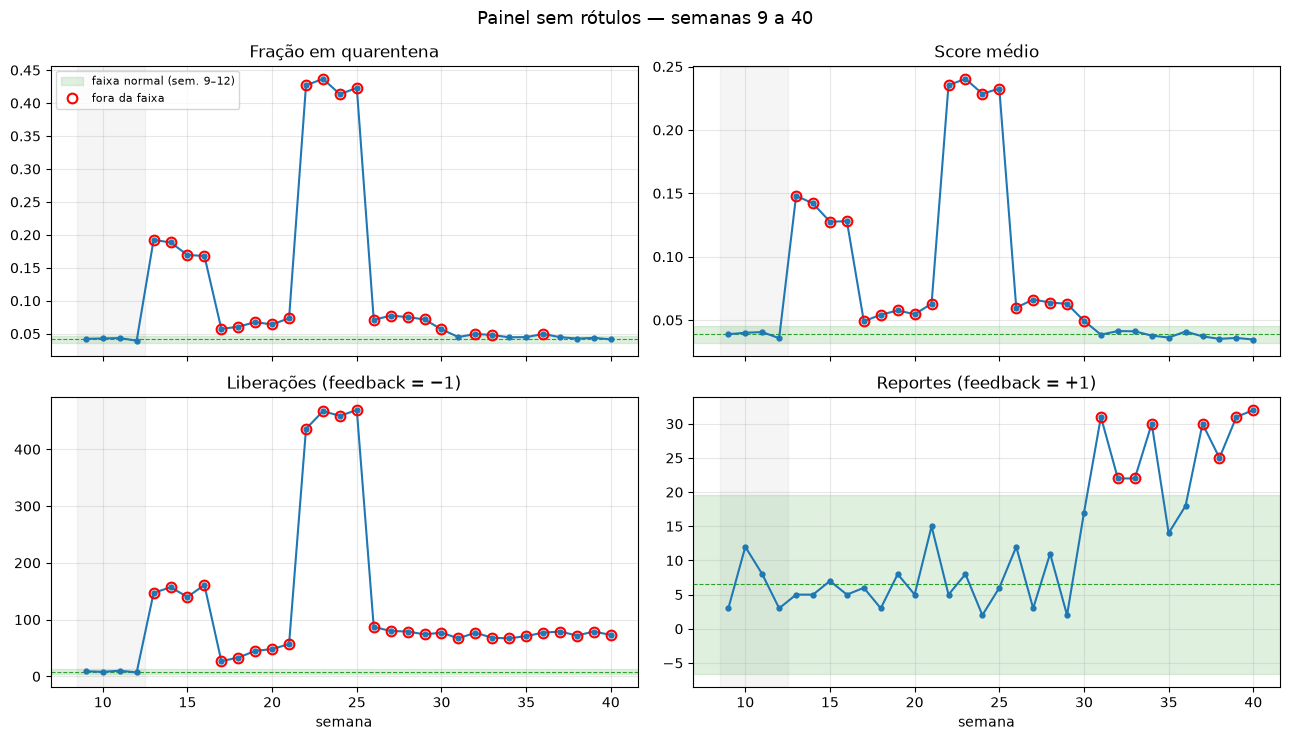

In [5]:
titulos = {"quarentena": "Fração em quarentena", "score_medio": "Score médio",
           "liberacoes": "Liberações (feedback = −1)", "reportes": "Reportes (feedback = +1)"}
fig, axs = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, c in zip(axs.ravel(), SERIES):
    y = painel[c]
    ax.axhspan(faixa.loc[c, "inf"], faixa.loc[c, "sup"], color="tab:green", alpha=0.15,
               label="faixa normal (sem. 9–12)")
    ax.axhline(faixa.loc[c, "media"], color="tab:green", lw=0.8, ls="--")
    ax.axvspan(8.5, 12.5, color="grey", alpha=0.08)
    ax.plot(y.index, y.values, "o-", ms=3.5, color="tab:blue")
    f = (y > faixa.loc[c, "sup"]) | (y < faixa.loc[c, "inf"])
    ax.plot(y.index[f], y[f], "o", ms=7, mfc="none", mec="red", mew=1.5, label="fora da faixa")
    ax.set_title(titulos[c]); ax.grid(alpha=0.3)
for ax in axs[1]:
    ax.set_xlabel("semana")
axs[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Painel sem rótulos — semanas 9 a 40", fontsize=13)
fig.tight_layout(); plt.show()

In [6]:
# períodos contíguos fora da faixa, por série
def periodos(mask):
    sem = list(mask[mask].index)
    blocos, ini = [], None
    for i, s in enumerate(sem):
        if ini is None: ini = s
        if i == len(sem) - 1 or sem[i + 1] != s + 1:
            blocos.append(f"{ini}" if ini == s else f"{ini}–{s}"); ini = None
    return ", ".join(blocos) or "—"

pd.DataFrame({c: {"acima": periodos(painel[c] > faixa.loc[c, "sup"]),
                  "abaixo": periodos(painel[c] < faixa.loc[c, "inf"])} for c in SERIES}).T

,acima,abaixo
quarentena,"13–30, 32–33, 36",—
score_medio,13–30,—
liberacoes,13–40,—
reportes,"31–34, 37–40",—


### a.4 Sinal complementar: de onde vêm as liberações

Ainda sem rótulo. Duas razões ajudam a ler as liberações: a **taxa de liberação** (liberações ÷ e-mails em quarentena) e o número de **caixas distintas** que liberaram. Se o modelo está mandando e-mail legítimo para a quarentena, as liberações se espalham por muitas caixas; se poucas caixas liberam muito, é concentração.

semana,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40
em_quarentena,132.000,130.000,129.000,113.000,569.000,579.000,501.000,503.00,168.000,189.000,205.00,192.00,218.000,1276.000,1388.000,1317.000,1297.000,223.00,228.000,231.000,216.000,179.00,136.000,150.000,144.000,133.000,131.000,156.000,147.000,129.000,132.000,131.000
liberacoes,9.000,8.000,10.000,7.000,147.000,157.000,140.000,161.00,27.000,33.000,45.00,48.00,57.000,436.000,467.000,459.000,469.000,87.00,80.000,79.000,74.000,77.00,67.000,77.000,68.000,67.000,71.000,77.000,79.000,72.000,79.000,73.000
caixas_que_liberaram,9.000,8.000,10.000,7.000,145.000,149.000,137.000,154.00,27.000,29.000,34.00,29.00,28.000,372.000,395.000,376.000,385.000,39.00,31.000,29.000,28.000,29.00,22.000,31.000,23.000,21.000,26.000,30.000,28.000,22.000,31.000,25.000
taxa_liberacao,0.068,0.062,0.078,0.062,0.258,0.271,0.279,0.32,0.161,0.175,0.22,0.25,0.261,0.342,0.336,0.349,0.362,0.39,0.351,0.342,0.343,0.43,0.493,0.513,0.472,0.504,0.542,0.494,0.537,0.558,0.598,0.557
liberacoes_por_caixa,1.000,1.000,1.000,1.000,1.010,1.050,1.020,1.05,1.000,1.140,1.32,1.66,2.040,1.170,1.180,1.220,1.220,2.23,2.580,2.720,2.640,2.66,3.050,2.480,2.960,3.190,2.730,2.570,2.820,3.270,2.550,2.920


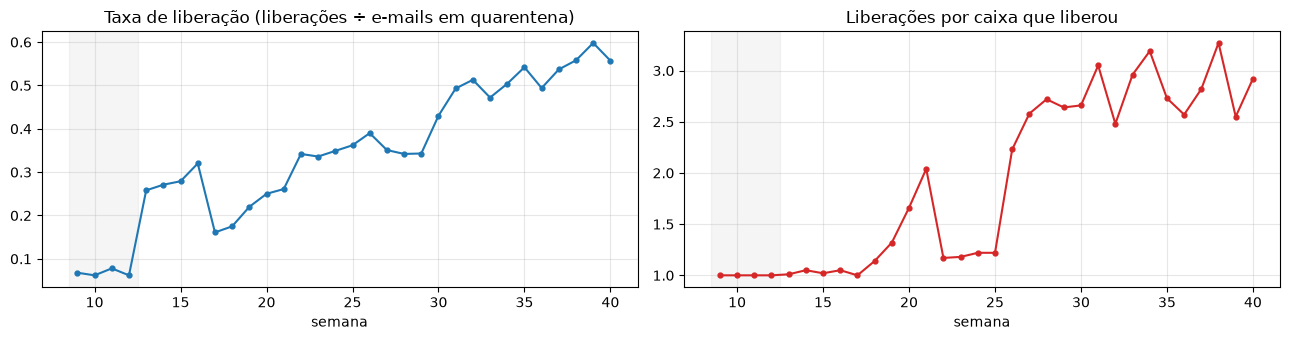

In [7]:
lib = prod[prod.feedback_usuario == -1]
extra = pd.DataFrame({
    "em_quarentena": prod.groupby("semana").alerta.sum(),
    "liberacoes": painel.liberacoes,
    "caixas_que_liberaram": lib.groupby("semana").destinatario.nunique(),
})
extra["taxa_liberacao"] = (extra.liberacoes / extra.em_quarentena).round(3)
extra["liberacoes_por_caixa"] = (extra.liberacoes / extra.caixas_que_liberaram).round(2)
display(extra.T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(extra.index, extra.taxa_liberacao, "o-", ms=3.5)
ax[0].set_title("Taxa de liberação (liberações ÷ e-mails em quarentena)")
ax[1].plot(extra.index, extra.liberacoes_por_caixa, "o-", ms=3.5, color="tab:red")
ax[1].set_title("Liberações por caixa que liberou")
for a in ax:
    a.axvspan(8.5, 12.5, color="grey", alpha=0.08); a.grid(alpha=0.3); a.set_xlabel("semana")
fig.tight_layout(); plt.show()

### a.5 Leitura do painel (sem olhar o rótulo)

**Linha de base.** Nas semanas 7 e 8 o modelo tem precisão 0,883 e 0,942 (média **0,913**) e recall 0,990 e 0,991 (média **0,991**) com limiar 0,30, o que confirma a escolha do limiar (precisão ≥ 0,90). O score recalculado com o `modelo_producao.joblib` é idêntico à coluna `score` (diferença máxima 0,0000, também em toda a produção): o modelo em uso é mesmo esse, e qualquer mudança no score vem da **entrada**, não do modelo.

Nas semanas 9–12 o painel é estável: ~4,2% em quarentena, score médio ~0,039, ~8,5 liberações e ~6,5 reportes por semana. A faixa dos reportes é larga (limite inferior negativo) porque o desvio de 4 semanas com contagens pequenas é grosseiro — é régua inicial, não prova.

| Período | O que o painel mostra | O que sugere |
|---|---|---|
| **13–16** | Degrau súbito: quarentena 17–19% (4,5×), score médio 0,13–0,15, liberações 140–161 (~17×). Reportes normais. Liberações espalhadas (≈1 por caixa). Volta abrupta na 17. | O modelo passou a mandar e-mail **legítimo** para a quarentena, e muitos usuários diferentes liberaram. Início e fim exatos em fronteira de semana: mudança brusca na entrada (pipeline ou tráfego novo). Custo de falso positivo, recall aparentemente intacto. |
| **17–21** | Quarentena 5,7% → 7,4% subindo aos poucos; liberações 27 → 57; score levemente acima. | Deslizamento **incremental** da entrada: cada vez mais e-mails caem acima do limiar. Mas as liberações já vêm de ~28 caixas, com até 2 por caixa. |
| **22–25** | Degrau ainda maior: quarentena 41–44% (10×), score ~0,23, liberações 436–469 (~55×), espalhadas por ~380 caixas. Reportes normais. Volta abrupta na 26. | Quase metade do tráfego em quarentena por 4 semanas, começo e fim em degrau: padrão típico de **quebra de pipeline** (uma feature passou a chegar errada). A conferir no item b). |
| **26–30** | Quarentena ~7%, liberações estáveis em ~75–87, mas de só ~30 caixas (≈2,7 por caixa). | Patamar elevado e concentrado — não parece usuário comum corrigindo falso positivo. |
| **31–40** | Quarentena e score **voltam à faixa** (~4,5%; 0,035–0,041). Reportes sobem para 22–32 por semana (3–5× a base, 8 de 10 semanas acima da faixa). Liberações continuam ~70/semana, com taxa de liberação de ~50% dos e-mails em quarentena (base: ~7%) e ~2,8 por caixa em ~25 caixas. | Quarentena normal + reportes subindo = **phishing chegando na caixa de entrada** sem o score acusar: o modelo está perdendo ataques que parecem normais para ele (suspeita de drift de conceito, item d). E metade da quarentena liberada por um grupo pequeno de caixas é um sinal de **feedback suspeito** (possível envenenamento, item f). |

Resumo: o painel sem rótulo mostra **três tipos de história**: (1) excesso de alerta em degraus (13–16 e 22–25) e em rampa (17–30), visível por quarentena + liberações subindo juntas; (2) a partir da semana 30–31, quarentena parada com reportes subindo, que é o primeiro sinal de que algo passa pelo filtro; (3) liberações que não acompanham a quarentena e vêm de poucas caixas desde ~18. O primeiro sinal sem rótulo de perda de recall é o **reporte acima da faixa na semana 31** (já 17 na semana 30).

---
## b) Qualidade dos dados

Para cada feature e semana de produção: fração de nulos, fração de zeros, número de valores distintos e fração fora da faixa [mín, máx] da referência (semanas 1–8).

In [8]:
ref_min, ref_max = ref[FEATURES].min(), ref[FEATURES].max()
g = prod.groupby("semana")
qualidade = pd.concat({
    "nulos":     g.apply(lambda d: d[FEATURES].isna().mean()),
    "zeros":     g.apply(lambda d: (d[FEATURES] == 0).mean()),
    "distintos": g.apply(lambda d: d[FEATURES].nunique()),
    "fora_faixa": g.apply(lambda d: ((d[FEATURES] < ref_min) | (d[FEATURES] > ref_max)).mean()),
}, axis=1)          # colunas: (medida, feature); linhas: semana

# referência para comparar
ref_q = pd.DataFrame({"min_ref": ref_min, "max_ref": ref_max,
                      "zeros_ref": (ref[FEATURES] == 0).mean(),
                      "distintos_ref_por_semana": ref.groupby("semana")[FEATURES].nunique().mean().round(0)})
display(ref_q.round(3))

# tabela completa em formato longo (feature x semana), para consulta
qual_longa = qualidade.stack(level=1, future_stack=True).rename_axis(["semana", "feature"])
print("Total de nulos em toda a produção:", int(prod[FEATURES].isna().sum().sum()))
qual_longa.round(3).head(13)

,min_ref,max_ref,zeros_ref,distintos_ref_por_semana
n_links,0.0,21.000,0.161,19.0
link_divergente,0.0,0.992,0.193,560.0
idade_dominio_dias,1.0,12000.000,0.000,1400.0
spf_dkim_ok,0.0,1.000,0.060,2.0
anexo_risco,0.0,1.000,0.984,2.0
palavras_urgencia,0.0,10.000,0.585,10.0
erros_ortografia,0.0,11.910,0.000,283.0
pede_credencial,0.0,1.000,0.935,2.0
pede_pagamento,0.0,1.000,0.915,2.0
remetente_externo,0.0,1.000,0.446,2.0


Total de nulos em toda a produção: 0


nulos  zeros  distintos  fora_faixa
semana feature                                                
9      n_links               0.0  0.161         18         0.0
       link_divergente       0.0  0.198        568         0.0
       idade_dominio_dias    0.0  0.000       1410         0.0
       spf_dkim_ok           0.0  0.066          2         0.0
       anexo_risco           0.0  0.984          2         0.0
       palavras_urgencia     0.0  0.579          9         0.0
       erros_ortografia      0.0  0.000        299         0.0
       pede_credencial       0.0  0.940          2         0.0
       pede_pagamento        0.0  0.922          2         0.0
       remetente_externo     0.0  0.448          2         0.0
       primeiro_contato      0.0  0.847          2         0.0
       tem_qr_code           0.0  0.977          2         0.0
       tamanho_kb            0.0  0.000        246         0.0

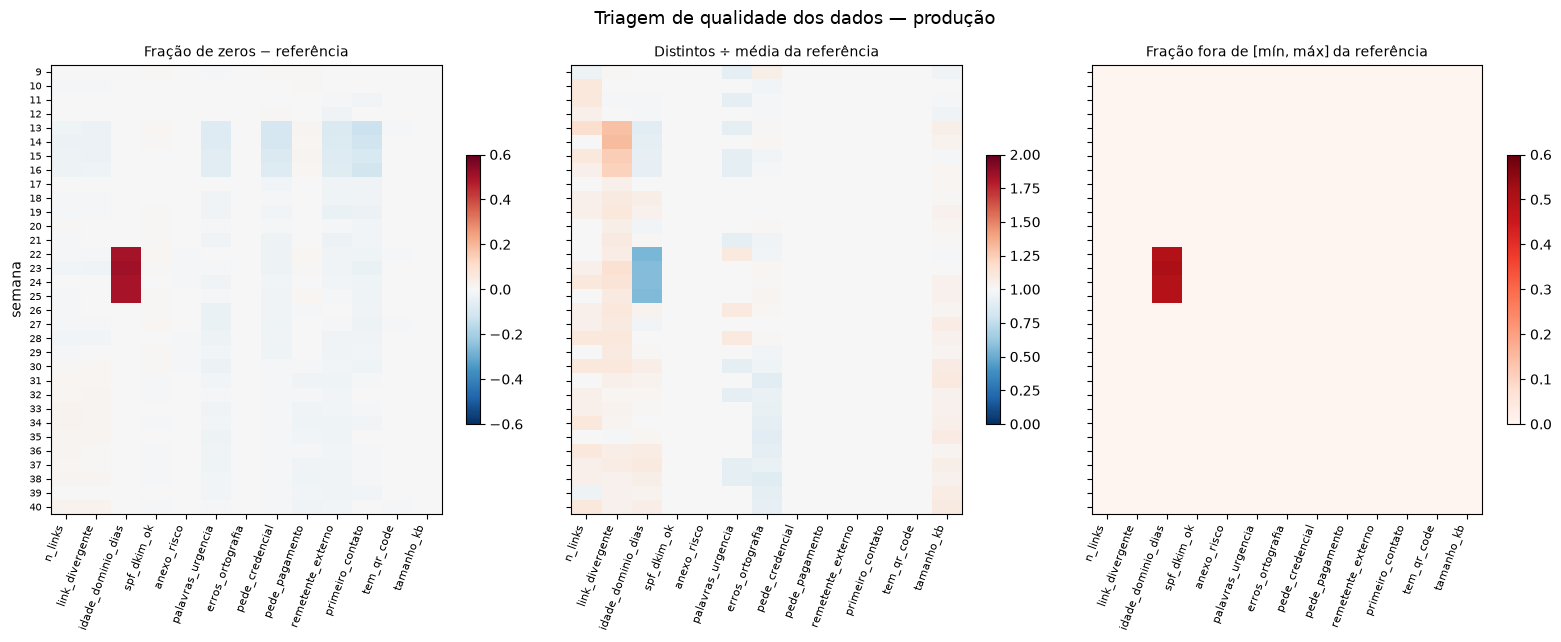

Células com 0 < fora_faixa ≤ 1%: 8 (máximo 0.0003) — cauda natural, não quebra


,,nulos,zeros,distintos,fora_faixa
semana,feature,,,,
22,idade_dominio_dias,0.0,0.501,761,0.501
23,idade_dominio_dias,0.0,0.509,789,0.509
24,idade_dominio_dias,0.0,0.496,798,0.496
25,idade_dominio_dias,0.0,0.494,777,0.494


In [9]:
# triagem: quanto cada medida se afasta da referência, por feature e semana
zeros_dif = qualidade["zeros"] - ref_q.zeros_ref                          # variação da fração de zeros
dist_rel  = qualidade["distintos"] / ref_q.distintos_ref_por_semana        # distintos relativo à referência

fig, axs = plt.subplots(1, 3, figsize=(16, 6.5), sharey=True)
for ax, (tit, M, cmap, vmin, vmax) in zip(axs, [
        ("Fração de zeros − referência", zeros_dif, "RdBu_r", -0.6, 0.6),
        ("Distintos ÷ média da referência", dist_rel, "RdBu_r", 0, 2),
        ("Fração fora de [mín, máx] da referência", qualidade["fora_faixa"], "Reds", 0, 0.6)]):
    im = ax.imshow(M.values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=70, ha="right", fontsize=8)
    ax.set_yticks(range(len(M.index))); ax.set_yticklabels(M.index, fontsize=7)
    ax.set_title(tit, fontsize=10); fig.colorbar(im, ax=ax, shrink=0.6)
axs[0].set_ylabel("semana")
fig.suptitle("Triagem de qualidade dos dados — produção", fontsize=13)
fig.tight_layout(); plt.show()

# caudas: valores pouco fora da faixa em fração ínfima são normais (amostra nova > amostra de referência)
cauda = qual_longa[(qual_longa.fora_faixa > 0) & (qual_longa.fora_faixa <= 0.01)]
print(f"Células com 0 < fora_faixa ≤ 1%: {len(cauda)} (máximo {cauda.fora_faixa.max():.4f}) — cauda natural, não quebra")

# alertas: fora da faixa em mais de 1% das linhas ou salto de zeros > 0,20
salto_zeros = (qual_longa.zeros - ref_q.zeros_ref.reindex(qual_longa.index.get_level_values(1)).values).abs()
alertas_q = qual_longa[(qual_longa.fora_faixa > 0.01) | (salto_zeros > 0.20)]
alertas_q.round(3)

In [10]:
# a feature quebrada em detalhe
FEAT_Q = "idade_dominio_dias"
det = pd.DataFrame({
    "zeros": qualidade["zeros"][FEAT_Q],
    "fora_faixa": qualidade["fora_faixa"][FEAT_Q],
    "distintos": qualidade["distintos"][FEAT_Q],
    "quarentena": painel.quarentena,
}).loc[18:29]
display(det.round(3))
SEMANAS_QUEBRA = sorted(qualidade.index[qualidade["fora_faixa"][FEAT_Q] > 0])
print("Semanas com a quebra:", SEMANAS_QUEBRA)
print(f"Fração de e-mails afetados nessas semanas: "
      f"{(prod[prod.semana.isin(SEMANAS_QUEBRA)][FEAT_Q] == 0).mean():.1%}")
print(f"Menor idade na referência: {ref[FEAT_Q].min()} dia(s); 1º percentil: {ref[FEAT_Q].quantile(.01):.0f} dias")

,zeros,fora_faixa,distintos,quarentena
semana,,,,
18,0.000,0.000,1491,0.061
19,0.000,0.000,1463,0.068
20,0.000,0.000,1364,0.064
21,0.000,0.000,1418,0.074
22,0.501,0.501,761,0.427
23,0.509,0.509,789,0.437
24,0.496,0.496,798,0.414
25,0.494,0.494,777,0.423
26,0.000,0.000,1444,0.071


Semanas com a quebra: [22, 23, 24, 25]
Fração de e-mails afetados nessas semanas: 50.0%
Menor idade na referência: 1.0 dia(s); 1º percentil: 19 dias


### b.1 Efeito da quebra sobre a quarentena

Duas medidas: (1) dentro das semanas da quebra, comparar e-mails com o valor quebrado e e-mails intactos; (2) experimento controlado: pegar semanas sem quebra, zerar a feature e recalcular o score com o modelo de produção.

In [11]:
w = prod[prod.semana.isin(SEMANAS_QUEBRA)].assign(quebrado=lambda d: d[FEAT_Q] == 0)
efeito = w.groupby("quebrado").agg(emails=("id_email", "size"), quarentena=("alerta", "mean"),
                                   score_medio=("score", "mean"),
                                   liberacoes=("feedback_usuario", lambda f: (f == -1).sum()),
                                   frac_phishing_verificado=("rotulo", "mean"))
display(efeito.round(3))

excesso = (efeito.loc[True, "quarentena"] - efeito.loc[False, "quarentena"]) * efeito.loc[True, "emails"]
print(f"Quarentena nas semanas {SEMANAS_QUEBRA[0]}–{SEMANAS_QUEBRA[-1]}: {w.alerta.mean():.1%} "
      f"(sem a quebra, os e-mails intactos ficam em {efeito.loc[False, 'quarentena']:.1%})")
print(f"E-mails a mais na quarentena por causa da quebra: ≈ {excesso:,.0f} "
      f"(≈ {excesso / len(SEMANAS_QUEBRA):,.0f} por semana)")
print(f"Liberações vindas de e-mails quebrados: {efeito.loc[True, 'liberacoes']} de {w.feedback_usuario.eq(-1).sum()}")

# experimento controlado: semanas vizinhas sem quebra, com a feature zerada
ctrl = prod[prod.semana.isin([20, 21, 26, 27])]
Xz = ctrl[FEATURES].copy(); Xz[FEAT_Q] = 0
s_z = modelo.predict_proba(Xz.values)[:, 1].round(4)
leg = ctrl.rotulo == 0
pd.DataFrame({"quarentena original": [ctrl.alerta.mean(), ctrl.alerta[leg].mean()],
              f"com {FEAT_Q} = 0": [(s_z >= LIMIAR).mean(), (s_z[leg] >= LIMIAR).mean()]},
             index=["todos os e-mails", "só legítimos"]).round(3)

,emails,quarentena,score_medio,liberacoes,frac_phishing_verificado
quebrado,,,,,
False,6211,0.07,0.060,142,0.055
True,6207,0.78,0.409,1689,0.059


Quarentena nas semanas 22–25: 42.5% (sem a quebra, os e-mails intactos ficam em 7.0%)
E-mails a mais na quarentena por causa da quebra: ≈ 4,404 (≈ 1,101 por semana)
Liberações vindas de e-mails quebrados: 1689 de 1831


,quarentena original,com idade_dominio_dias = 0
todos os e-mails,0.071,0.774
só legítimos,0.021,0.761


### b.2 Leitura

**A quebra.** Nulos não aparecem em nenhuma feature, e as features binárias mantêm dois valores distintos o tempo todo. A triagem acusa **uma única feature**: `idade_dominio_dias` vale **0** em **~50% dos e-mails nas semanas 22, 23, 24 e 25** (50,1%, 50,9%, 49,6%, 49,4%; 50,0% no total). O valor 0 **nunca existe na referência** (mínimo = 1 dia), por isso a fração fora da faixa salta de 0 para ~0,50 e o número de valores distintos cai quase pela metade (~1.400 → ~780). O defeito começa e termina em fronteira de semana, atinge uma feature só e um valor repetido em metade das linhas: os três sinais de quebra de pipeline da seção 2.4. É compatível com a consulta WHOIS falhando em metade das consultas e o extrator gravando 0 no lugar de "sem resposta".

**Efeito na quarentena.** Para o modelo, um domínio "de 0 dias" é o sinal mais forte de phishing. Nas semanas 22–25 os e-mails com idade 0 vão **78%** para a quarentena, contra **7%** dos intactos nas mesmas semanas, embora a fração de phishing verificado seja a mesma nos dois grupos (~5,9% × ~5,5%): é o mesmo tráfego medido errado. A quebra coloca **≈ 4.400 e-mails a mais** na quarentena (~1.100 por semana), leva a fração de 7% para ~42% e responde por ~1.690 das ~1.830 liberações do período. No experimento controlado, zerar a feature em semanas sãs leva a quarentena de 7% para 77% e a dos legítimos de 2% para 76%: o efeito é causal, não coincidência.

**Por que não é drift.** Drift é o mundo mudando: P(X) ou P(y|X) dos e-mails reais. Aqui os e-mails são os mesmos (mesma prevalência de phishing, mesmas outras features); mudou a **medição**. Corrigir o modelo não resolve: um modelo retreinado para "aceitar" idade 0 estaria aprendendo um defeito.

**O que fazer com o pipeline.** Consertar o extrator (tratar falha do WHOIS como valor ausente explícito, nunca 0), colocar uma validação de esquema na entrada do modelo (rejeitar ou sinalizar valores fora de [mín, máx] da referência, alertar se a fração de zeros/valores repetidos de uma feature muda de uma semana para outra) e, enquanto a feature estiver quebrada, imputar um valor neutro (ex.: mediana da referência) ou desviar o e-mail para uma regra de contingência em vez de pontuar com 0. Reprocessar os e-mails afetados que ainda estejam em quarentena.

**O que fazer com essas semanas no retreino.** As semanas **22–25 ficam fora de qualquer janela de retreino** (ou, no mínimo, as linhas com idade 0 são descartadas). Treinar com elas ensinaria que "idade 0" existe e é comum entre legítimos; além disso, o `rotulo_pipeline` dessas semanas está contaminado pelas ~1.100 quarentenas extras por semana. Essa é a diferença entre S1 e S1 limpa no item e).

**Observação.** As semanas 13–16 também mexem em várias features (`pede_credencial`, `remetente_externo`, `primeiro_contato`, `palavras_urgencia`, `link_divergente`), mas só como mudança de proporção entre valores que já existiam na referência, sem valor impossível nem valor repetido. Isso é cara de **drift de dados** (tráfego diferente chegando), assunto do item c).

---
## c) Drift de dados

PSI (função da seção 5) de cada feature e do `score`, por semana de produção, contra a referência inteira (semanas 1–8). KS de duas amostras (`scipy.stats.ks_2samp`) nas mesmas combinações.

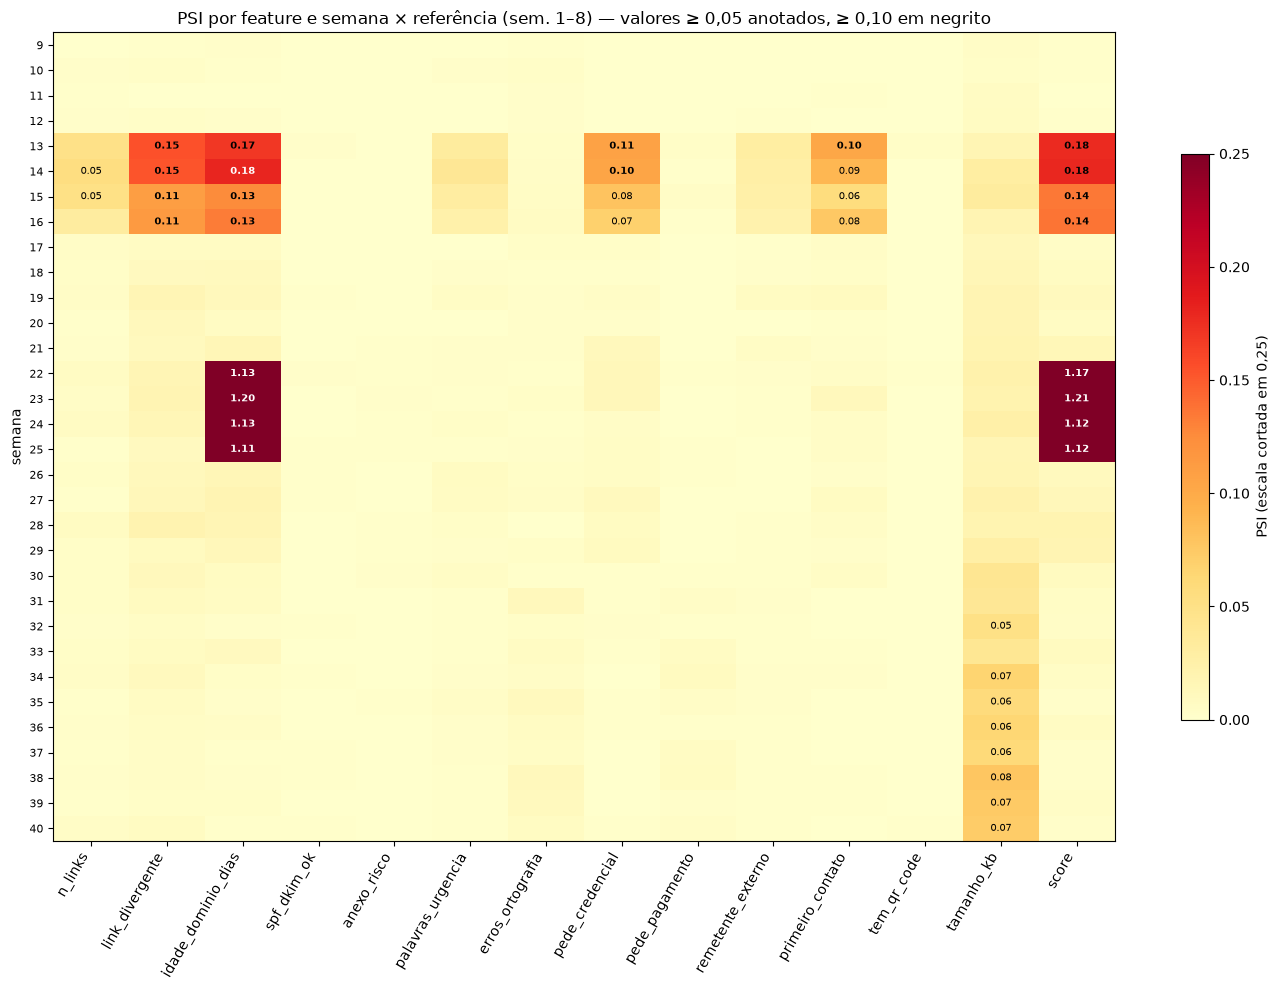

In [12]:
COLS = FEATURES + ["score"]
semanas = sorted(prod.semana.unique())
grupos = {s: d for s, d in prod.groupby("semana")}

PSI = pd.DataFrame({c: [psi(ref[c], grupos[s][c]) for s in semanas] for c in COLS}, index=semanas)
KSp = pd.DataFrame({c: [ks_2samp(ref[c], grupos[s][c]).pvalue for s in semanas] for c in COLS}, index=semanas)
PSI.index.name = KSp.index.name = "semana"

fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(PSI.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=0.25)
for i in range(PSI.shape[0]):
    for j in range(PSI.shape[1]):
        v = PSI.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v >= 0.18 else "black", fontweight="bold" if v >= 0.10 else None)
ax.set_xticks(range(len(COLS))); ax.set_xticklabels(COLS, rotation=60, ha="right")
ax.set_yticks(range(len(semanas))); ax.set_yticklabels(semanas, fontsize=8); ax.set_ylabel("semana")
cb = fig.colorbar(im, ax=ax, shrink=0.7); cb.set_label("PSI (escala cortada em 0,25)")
ax.set_title("PSI por feature e semana × referência (sem. 1–8) — valores ≥ 0,05 anotados, ≥ 0,10 em negrito")
fig.tight_layout(); plt.show()

In [13]:
# KS: em quantas semanas p < 0,01, e o maior PSI da feature
resumo_c = pd.DataFrame({
    "semanas_KS_p<0,01": (KSp < 0.01).sum(),
    "semanas_PSI>=0,10": (PSI >= 0.10).sum(),
    "PSI_mediano": PSI.median().round(4),
    "PSI_maximo": PSI.max().round(3),
    "importancia_no_modelo": pd.Series(modelo.feature_importances_, FEATURES).round(3),
}).sort_values("semanas_KS_p<0,01", ascending=False)
print(f"Testes KS: {KSp[FEATURES].size} (features) — esperados por acaso com p<0,01: "
      f"≈ {0.01 * KSp[FEATURES].size:.0f}; observados: {(KSp[FEATURES] < 0.01).sum().sum()}")
resumo_c

Testes KS: 416 (features) — esperados por acaso com p<0,01: ≈ 4; observados: 92


,"semanas_KS_p<0,01","semanas_PSI>=0,10",PSI_mediano,PSI_maximo,importancia_no_modelo
tamanho_kb,28,0,0.0225,0.078,0.050
idade_dominio_dias,17,8,0.0086,1.199,0.398
score,16,8,0.0074,1.211,NaN
link_divergente,16,4,0.0093,0.155,0.196
palavras_urgencia,7,0,0.0021,0.040,0.016
remetente_externo,6,0,0.0016,0.030,0.002
primeiro_contato,6,1,0.0026,0.103,0.030
pede_credencial,5,2,0.0027,0.107,0.110
n_links,5,0,0.0032,0.055,0.047
erros_ortografia,2,0,0.0033,0.011,0.073


### c.1 Períodos e features com PSI ≥ 0,10

In [14]:
rel = PSI.rename_axis(columns="variavel").stack().rename("PSI").reset_index()
rel = rel[rel.PSI >= 0.10]
tab_rel = (rel.groupby("variavel")
              .agg(semanas=("semana", lambda s: periodos(pd.Series(True, index=sorted(s)))),
                   PSI_min=("PSI", "min"), PSI_max=("PSI", "max"))
              .sort_values("PSI_max", ascending=False))
display(tab_rel.round(3))

# como as features em drift mudaram nas semanas 13–16 (média: referência × 9–12 × 13–16 × 17–20)
drift_feats = ["link_divergente", "idade_dominio_dias", "pede_credencial", "primeiro_contato", "n_links",
               "palavras_urgencia", "remetente_externo"]
comp = pd.DataFrame({"referência 1–8": ref[drift_feats].mean(),
                     "prod 9–12": prod[prod.semana.between(9, 12)][drift_feats].mean(),
                     "prod 13–16": prod[prod.semana.between(13, 16)][drift_feats].mean(),
                     "prod 17–20": prod[prod.semana.between(17, 20)][drift_feats].mean()})
comp.round(3)

,semanas,PSI_min,PSI_max
variavel,,,
score,"13–16, 22–25",0.135,1.211
idade_dominio_dias,"13–16, 22–25",0.126,1.199
link_divergente,13–16,0.110,0.155
pede_credencial,13–14,0.104,0.107
primeiro_contato,13,0.103,0.103


,referência 1–8,prod 9–12,prod 13–16,prod 17–20
link_divergente,0.115,0.115,0.193,0.129
idade_dominio_dias,4364.077,4365.875,3665.421,4233.137
pede_credencial,0.065,0.063,0.157,0.079
primeiro_contato,0.148,0.153,0.261,0.172
n_links,2.629,2.587,3.010,2.702
palavras_urgencia,0.778,0.775,0.973,0.811
remetente_externo,0.554,0.560,0.634,0.578


### c.2 Significância × relevância: `tamanho_kb`

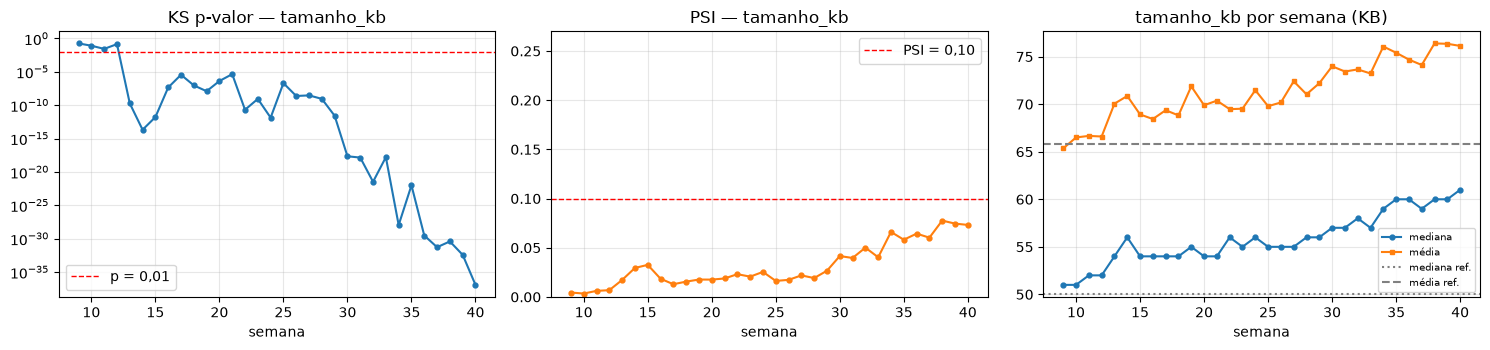

tamanho_kb: KS p<0,01 em 28 de 32 semanas; PSI máximo 0.078; mediana 50 KB → 61 KB na semana 40; importância no modelo 0.050


In [15]:
tam = prod.groupby("semana").tamanho_kb.agg(["median", "mean"])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(KSp.index, KSp.tamanho_kb, "o-", ms=3.5); ax[0].set_yscale("log")
ax[0].axhline(0.01, color="red", ls="--", lw=1, label="p = 0,01"); ax[0].legend()
ax[0].set_title("KS p-valor — tamanho_kb")
ax[1].plot(PSI.index, PSI.tamanho_kb, "o-", ms=3.5, color="tab:orange")
ax[1].axhline(0.10, color="red", ls="--", lw=1, label="PSI = 0,10"); ax[1].set_ylim(0, 0.27); ax[1].legend()
ax[1].set_title("PSI — tamanho_kb")
ax[2].plot(tam.index, tam["median"], "o-", ms=3.5, label="mediana")
ax[2].plot(tam.index, tam["mean"], "s-", ms=3, label="média")
ax[2].axhline(ref.tamanho_kb.median(), color="grey", ls=":", label="mediana ref.")
ax[2].axhline(ref.tamanho_kb.mean(), color="grey", ls="--", label="média ref."); ax[2].legend(fontsize=7)
ax[2].set_title("tamanho_kb por semana (KB)")
for a in ax: a.grid(alpha=0.3); a.set_xlabel("semana")
fig.tight_layout(); plt.show()
print(f"tamanho_kb: KS p<0,01 em {(KSp.tamanho_kb < 0.01).sum()} de 32 semanas; "
      f"PSI máximo {PSI.tamanho_kb.max():.3f}; mediana {ref.tamanho_kb.median():.0f} KB → "
      f"{tam['median'].iloc[-1]:.0f} KB na semana 40; importância no modelo {modelo.feature_importances_[FEATURES.index('tamanho_kb')]:.3f}")

### c.3 O que o painel mostra e o PSI não mostra

semana,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40
PSI_max_features,0.017,0.022,0.020,0.027,0.042,0.040,0.050,0.040,0.066,0.058,0.064,0.060,0.078,0.075,0.073
PSI_score,0.011,0.013,0.020,0.018,0.008,0.006,0.004,0.008,0.005,0.003,0.006,0.002,0.002,0.004,0.003
quarentena,0.071,0.077,0.075,0.072,0.057,0.045,0.050,0.048,0.045,0.045,0.050,0.045,0.043,0.044,0.041
reportes,12.000,3.000,11.000,2.000,17.000,31.000,22.000,22.000,30.000,14.000,18.000,30.000,25.000,31.000,32.000
liberacoes,87.000,80.000,79.000,74.000,77.000,67.000,77.000,68.000,67.000,71.000,77.000,79.000,72.000,79.000,73.000


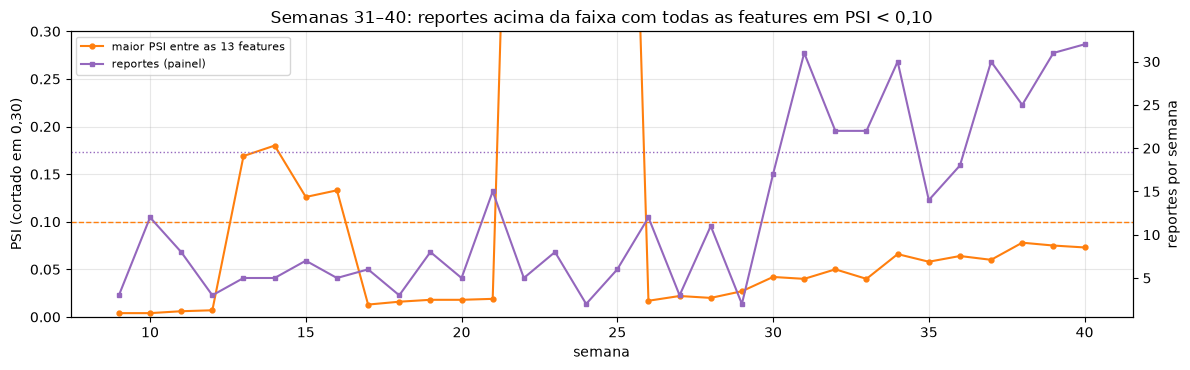

In [16]:
cmp = pd.DataFrame({
    "PSI_max_features": PSI[FEATURES].max(axis=1).round(3),
    "PSI_score": PSI.score.round(3),
    "quarentena": painel.quarentena.round(3),
    "reportes": painel.reportes,
    "liberacoes": painel.liberacoes,
})
display(cmp.loc[26:40].T)

fig, ax1 = plt.subplots(figsize=(12, 3.8))
ax1.plot(cmp.index, cmp.PSI_max_features, "o-", ms=3.5, color="tab:orange", label="maior PSI entre as 13 features")
ax1.axhline(0.10, color="tab:orange", ls="--", lw=1)
ax1.set_ylim(0, 0.30); ax1.set_ylabel("PSI (cortado em 0,30)"); ax1.set_xlabel("semana")
ax2 = ax1.twinx()
ax2.plot(cmp.index, cmp.reportes, "s-", ms=3.5, color="tab:purple", label="reportes (painel)")
ax2.axhline(faixa.loc["reportes", "sup"], color="tab:purple", ls=":", lw=1)
ax2.set_ylabel("reportes por semana")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8); ax1.grid(alpha=0.3)
ax1.set_title("Semanas 31–40: reportes acima da faixa com todas as features em PSI < 0,10")
fig.tight_layout(); plt.show()

### c.4 Respostas

**1. Drift de dados relevante (PSI ≥ 0,10).** Há dois episódios, e só um deles é drift:

- **Semanas 13–16: drift de dados de verdade.** `idade_dominio_dias` (0,13–0,18), `link_divergente` (0,11–0,16), `pede_credencial` (0,10–0,11 nas semanas 13 e 14) e `primeiro_contato` (0,10 na semana 13), além do `score` (0,14–0,18). Outras features se mexem abaixo do corte (`n_links`, `palavras_urgencia`, `remetente_externo`, `primeiro_contato` nas semanas 14–16). Todas voltam a PSI < 0,02 na semana 17: é uma mudança **súbita e temporária** (um retângulo, na linguagem da figura 3). Chegou um bloco de e-mail com domínios mais novos, mais links divergentes, mais pedidos de login e mais remetentes de primeiro contato. É o mesmo tráfego que, no item a), mandou a quarentena para ~19% com liberações espalhadas por ~150 caixas: o drift caiu numa região que o modelo associa a phishing e virou falso positivo.
- **Semanas 22–25: não é drift.** `idade_dominio_dias` com PSI 1,11–1,20 e `score` com 1,12–1,21 são a **quebra de pipeline** do item b) (zeros em 50% das linhas). O PSI acusa, mas a resposta é consertar o extrator, não o modelo.

Fora disso, nenhuma feature passa de 0,10 em semana nenhuma.

**2. Significância sem relevância: `tamanho_kb`.** O KS dá p < 0,01 em **28 das 32 semanas**, mais que qualquer outra feature, mas o PSI dela nunca passa de **0,078**. É um deslizamento lento e pequeno: a mediana sobe de 50 KB na referência para ~61 KB na semana 40 (e-mails ficando um pouco maiores com o tempo). Com ~24 mil linhas na referência e ~3 mil por semana, o KS detecta diferenças minúsculas (seção 2.6). Além disso, a feature tem importância **0,05** no modelo, e quarentena e score ficam na faixa normal nas semanas 31–40, quando o KS dela é mais forte. Não deve virar alarme porque (i) o p-valor mede se existe diferença, não se ela importa; (ii) com 13 features × 32 semanas = 416 testes, ~4 alarmes por semana viriam só do acaso; e (iii) a mudança não tem efeito sobre a saída do modelo. O lugar dela é num acompanhamento de tendência (PSI ou média móvel), não num alarme.

**3. O que o painel mostrou e o PSI não mostra.** A **subida dos reportes nas semanas 31–40** (22–32 por semana, 3 a 5 vezes a base). Nessas semanas o maior PSI entre as 13 features fica entre 0,04 e 0,08 (puxado só pelo `tamanho_kb`), e o PSI do score, < 0,01. A quarentena está normal. Phishing chegando na caixa sem nenhuma feature mudar é a assinatura de **drift de conceito**: mudou P(y | X), não P(X). Os novos phishing têm valores de feature que, para o modelo, parecem legítimos. Como o phishing é ~5–6% do tráfego, mesmo uma mudança grande dentro da classe mal mexe na distribuição do tráfego inteiro (seção 2.7). O item d) mede isso com o rótulo.

Dois outros sinais do painel também escapam do PSI. (a) As **liberações altas e concentradas em poucas caixas** desde ~18: são comportamento dos usuários, não uma propriedade do e-mail, e não aparecem em P(X) (item f). (b) A **quarentena moderadamente alta nas semanas 17–30** (6–8%) tem PSI do score de no máximo 0,02. Uma subida de 4% para 7% fica toda dentro do decil mais alto do score, e o PSI por decis a enxerga pouco. Conferindo retrospectivamente com o rótulo, parte disso é **mudança de prevalência** (phishing passa de ~3,8% para ~5,5–6% a partir das semanas 19–21), que o PSI das features também quase não vê.

---
## d) Drift de conceito

### d.1 Precisão e recall por semana (avaliação retrospectiva) e o que se sabia em cada semana

In [17]:
def metricas(d, col_pred="alerta"):
    return pd.Series({"precisao": precision_score(d.rotulo, d[col_pred], zero_division=0),
                      "recall": recall_score(d.rotulo, d[col_pred], zero_division=0),
                      "prevalencia": d.rotulo.mean()})

desemp = prod.groupby("semana").apply(metricas)
LIM_REC = REC_BASE - 0.15
print(f"Recall de base (média sem. 7–8) = {REC_BASE:.4f}  →  limite = {LIM_REC:.4f}")

# no início da semana t, a última semana com rótulo é t − 3
sabido = desemp[["precisao", "recall"]].shift(3).add_suffix("_conhecido")
sabido["semana_do_rotulo"] = pd.Series(desemp.index, index=desemp.index).shift(3).astype("Int64")
tab_d = desemp.join(sabido)
display(tab_d.round(3))

sem_queda = desemp.index[desemp.recall < LIM_REC][0]
sem_conhecida = sabido.index[sabido.recall_conhecido < LIM_REC][0]
print(f"Recall cai abaixo de {LIM_REC:.3f} na semana {sem_queda} "
      f"(recall = {desemp.recall[sem_queda]:.3f}); a queda passa a ser conhecida no início da semana {sem_conhecida}.")

Recall de base (média sem. 7–8) = 0.9906  →  limite = 0.8406


,precisao,recall,prevalencia,precisao_conhecido,recall_conhecido,semana_do_rotulo
semana,,,,,,
9,0.894,0.967,0.039,NaN,NaN,<NA>
10,0.923,0.976,0.040,NaN,NaN,<NA>
11,0.884,0.974,0.039,NaN,NaN,<NA>
12,0.876,0.980,0.035,0.894,0.967,9
13,0.221,0.947,0.045,0.923,0.976,10
14,0.187,0.964,0.036,0.884,0.974,11
15,0.216,0.991,0.037,0.876,0.980,12
16,0.207,0.963,0.036,0.221,0.947,13
17,0.595,0.990,0.034,0.187,0.964,14


Recall cai abaixo de 0.841 na semana 30 (recall = 0.701); a queda passa a ser conhecida no início da semana 33.


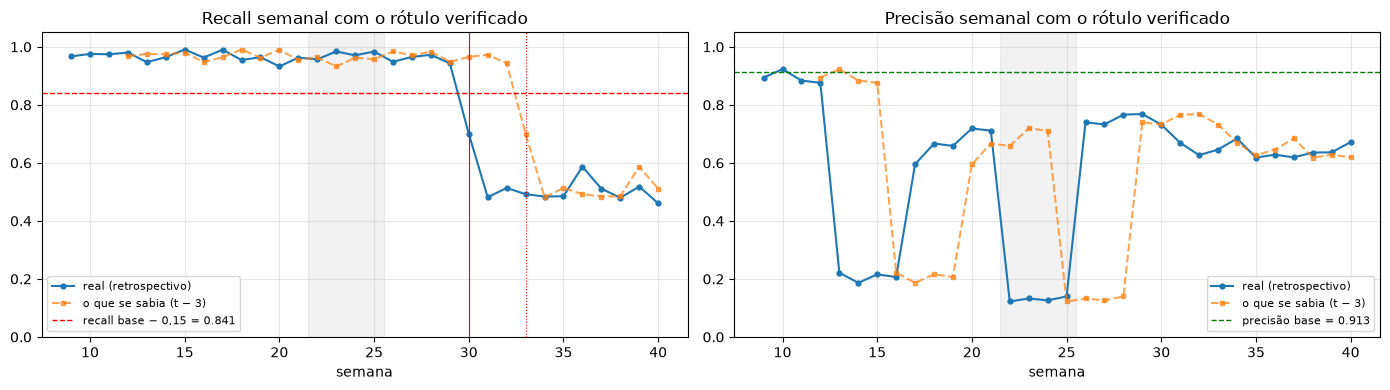

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, m in zip(ax, ["recall", "precisao"]):
    a.plot(desemp.index, desemp[m], "o-", ms=3.5, label="real (retrospectivo)")
    a.plot(sabido.index, sabido[m + "_conhecido"], "s--", ms=3, alpha=0.7, label="o que se sabia (t − 3)")
    a.axvspan(21.5, 25.5, color="grey", alpha=0.1)
    a.grid(alpha=0.3); a.set_xlabel("semana"); a.set_ylim(0, 1.05)
    a.set_title({"recall": "Recall", "precisao": "Precisão"}[m] + " semanal com o rótulo verificado")
ax[0].axhline(LIM_REC, color="red", ls="--", lw=1, label=f"recall base − 0,15 = {LIM_REC:.3f}")
ax[0].axvline(sem_queda, color="red", lw=0.8); ax[0].axvline(sem_conhecida, color="red", lw=0.8, ls=":")
ax[1].axhline(PREC_BASE, color="green", ls="--", lw=1, label=f"precisão base = {PREC_BASE:.3f}")
for a in ax: a.legend(fontsize=8)
fig.tight_layout(); plt.show()

### d.2 Page-Hinkley no fluxo de erros

Fluxo: só os e-mails de phishing (`rotulo = 1`) a partir da semana 9, em ordem de semana e de `id_email`; x = 1 se o e-mail **não** foi para a quarentena (phishing perdido). `PageHinkley(delta=0.05, lamb=8)` da seção 5.

Page-Hinkley dispara no 3033º e-mail de phishing do fluxo (e088244), semana 30 — o 16º phishing daquela semana (de 187).
Média do sinal (taxa de phishing perdido acumulada) no disparo: 0.037.  O rótulo da semana 30 fica disponível no início da semana 33.


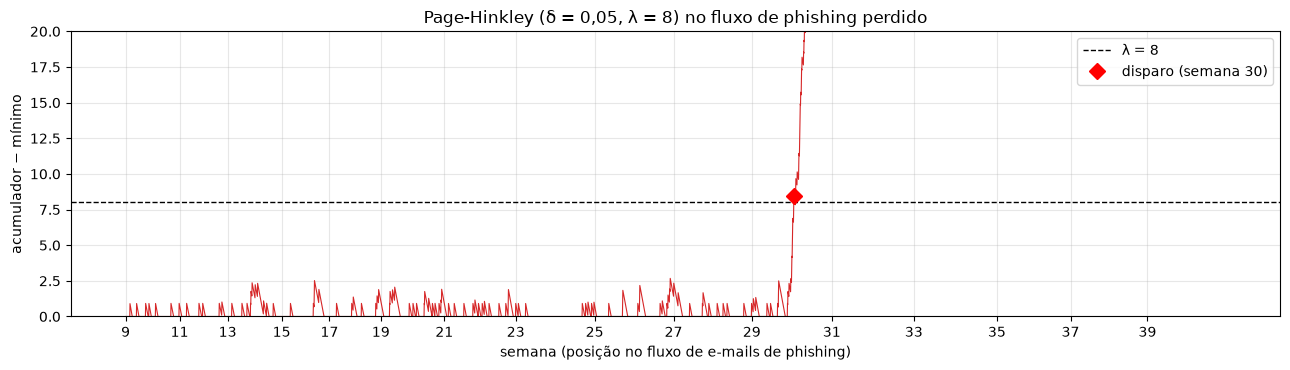

In [19]:
fluxo = prod[prod.rotulo == 1].sort_values(["semana", "id_email"]).reset_index(drop=True)
fluxo["erro"] = 1 - fluxo.alerta

ph = PageHinkley(delta=0.05, lamb=8.0)
acum, disparo = [], None
for i, x in enumerate(fluxo.erro):
    alarme = ph.atualizar(x)
    acum.append(ph.m - ph.m_min)
    if alarme and disparo is None:
        disparo, media_no_disparo = i, ph.media
fluxo["ph_acima_do_min"] = acum

sem_ph = fluxo.semana[disparo]
pos_na_semana = disparo - fluxo.index[fluxo.semana == sem_ph][0] + 1
print(f"Page-Hinkley dispara no {disparo + 1}º e-mail de phishing do fluxo ({fluxo.id_email[disparo]}), "
      f"semana {sem_ph} — o {pos_na_semana}º phishing daquela semana "
      f"(de {(fluxo.semana == sem_ph).sum()}).")
print(f"Média do sinal (taxa de phishing perdido acumulada) no disparo: {media_no_disparo:.3f}.  O rótulo da semana {sem_ph} fica disponível no início da semana {sem_ph + 3}.")

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(fluxo.index, fluxo.ph_acima_do_min, lw=0.8, color="tab:red")
ax.axhline(8, color="k", ls="--", lw=1, label="λ = 8")
ax.plot(disparo, fluxo.ph_acima_do_min[disparo], "D", color="red", ms=8, label=f"disparo (semana {sem_ph})")
inicios = fluxo.groupby("semana").apply(lambda d: d.index[0])
ax.set_xticks(inicios.values[::2]); ax.set_xticklabels(inicios.index[::2])
ax.set_xlabel("semana (posição no fluxo de e-mails de phishing)"); ax.set_ylabel("acumulador − mínimo")
ax.set_ylim(0, 20); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Page-Hinkley (δ = 0,05, λ = 8) no fluxo de phishing perdido")
fig.tight_layout(); plt.show()

### d.3 Linha do tempo: quando cada sinal fica disponível

In [20]:
sem_rep = painel.index[(painel.reportes > faixa.loc["reportes", "sup"]) & (painel.index >= 26)][0]
linha = pd.DataFrame([
    ("Recall real cai abaixo do limite (retrospectivo)", sem_queda, "—"),
    ("Reportes acima da faixa normal (painel, sem rótulo)", sem_rep, f"fim da semana {sem_rep} / início da {sem_rep + 1}"),
    ("Page-Hinkley dispara no fluxo de erros", sem_ph, f"início da semana {sem_ph + 3}"),
    ("Recall conhecido (t − 3) abaixo do limite", sem_queda, f"início da semana {sem_conhecida}"),
], columns=["sinal", "semana a que o dado se refere", "quando você ficaria sabendo"])
linha

,sinal,semana a que o dado se refere,quando você ficaria sabendo
0,Recall real cai abaixo do limite (retrospectivo),30,—
1,"Reportes acima da faixa normal (painel, sem ró...",31,fim da semana 31 / início da 32
2,Page-Hinkley dispara no fluxo de erros,30,início da semana 33
3,Recall conhecido (t − 3) abaixo do limite,30,início da semana 33


### d.4 Por que o PSI das features não acusou

O PSI compara o tráfego **inteiro** com a referência. Para ver a mudança, é preciso olhar **dentro da classe phishing**, o que só o rótulo permite (aqui, de forma retrospectiva).

In [21]:
ref_ph = ref[ref.rotulo == 1]
novo = prod[prod.semana.between(31, 40)]
novo_ph = novo[novo.rotulo == 1]
perdidos = novo_ph[novo_ph.alerta == 0]

psi_c = pd.DataFrame({
    "PSI tráfego todo (31–40)": [psi(ref[c], novo[c]) for c in FEATURES],
    "PSI só phishing (31–40)": [psi(ref_ph[c], novo_ph[c]) for c in FEATURES],
    "média phishing ref.": ref_ph[FEATURES].mean().values,
    "média phishing 26–29": prod[prod.semana.between(26, 29) & (prod.rotulo == 1)][FEATURES].mean().values,
    "média phishing perdido 31–40": perdidos[FEATURES].mean().values,
    "média legítimo ref.": ref[ref.rotulo == 0][FEATURES].mean().values,
}, index=FEATURES)
print(f"Prevalência de phishing nas semanas 31–40: {novo.rotulo.mean():.3f}; "
      f"phishing perdido: {len(perdidos)} de {len(novo_ph)} ({len(perdidos) / len(novo_ph):.1%})")
psi_c.sort_values("PSI só phishing (31–40)", ascending=False).round(3)

Prevalência de phishing nas semanas 31–40: 0.058; phishing perdido: 892 de 1785 (50.0%)


,PSI tráfego todo (31–40),PSI só phishing (31–40),média phishing ref.,média phishing 26–29,média phishing perdido 31–40,média legítimo ref.
n_links,0.002,3.608,3.352,3.228,0.363,2.600
idade_dominio_dias,0.002,1.322,91.045,105.096,3645.911,4534.719
erros_ortografia,0.005,1.284,2.222,1.621,0.313,0.698
pede_pagamento,0.004,0.830,0.093,0.102,0.842,0.084
link_divergente,0.004,0.796,0.668,0.668,0.092,0.093
primeiro_contato,0.001,0.594,0.794,0.765,0.128,0.122
tamanho_kb,0.057,0.477,36.374,36.566,77.720,67.037
spf_dkim_ok,0.001,0.388,0.423,0.452,0.955,0.960
pede_credencial,0.001,0.327,0.703,0.701,0.063,0.040
palavras_urgencia,0.002,0.174,2.578,2.411,1.502,0.707


### d.5 Leitura

**Desempenho por semana.** O recall fica entre 0,93 e 0,99 da semana 9 à 29, inclusive durante o drift de dados (13–16) e a quebra (22–25). Esses dois episódios derrubam a **precisão** (0,19–0,22 e 0,12–0,14), não o recall. Na **semana 30** o recall cai para **0,701**, abaixo do limite de 0,991 − 0,15 = **0,841**, e daí em diante fica em ~0,46–0,59. Metade do phishing passa (892 de 1.785 nas semanas 31–40). A mudança é **súbita e permanente** (degrau, figura 3). Pela tabela do que se sabia, a queda só fica **conhecida no início da semana 33**, três semanas depois de começar.

**Page-Hinkley.** O detector fica quieto nas semanas 9–29, quando a taxa de erro oscila em torno de 3–5%, e **dispara na semana 30**, no 16º e-mail de phishing daquela semana (3.033º do fluxo). A taxa acumulada de erro ainda era 0,037: o alarme reage à sequência recente de erros, não à média. Mas o fluxo de erros depende do rótulo, e o rótulo da semana 30 só fica disponível no **início da semana 33**. Na prática, o Page-Hinkley avisa na mesma data que a tabela t − 3. O ganho dele é dizer **onde** dentro da semana a mudança começou e funcionar com o rótulo chegando e-mail a e-mail, não antecipar a descoberta.

**Comparação com o sinal sem rótulo.** No item a), os **reportes** saem da faixa na **semana 31** (31 reportes; já eram 17 na 30), o que se sabe no fim da semana 31 ou início da 32. É **uma semana antes** do rótulo e do Page-Hinkley. O preço é o ruído: com 4 semanas de base, a faixa dos reportes é larga, e um ponto isolado (como 15 na semana 21) não basta. Na prática o reporte serve para **abrir investigação** e priorizar o SOC a rotular as semanas suspeitas, e o rótulo confirma.

**Por que o PSI não acusou.** Nas semanas 31–40 o PSI do tráfego todo fica entre 0,000 e 0,057 em todas as features. Dentro do phishing, porém, ele vai a 3,6 (`n_links`), 1,3 (`idade_dominio_dias`, `erros_ortografia`), 0,83 (`pede_pagamento`) e 0,80 (`link_divergente`). Os phishing perdidos têm cara de e-mail legítimo: domínio antigo (~3.600 dias contra ~90 do phishing da referência), SPF/DKIM ok (0,96), quase sem links (0,36) e sem link divergente, poucos erros, sem pedir credencial e sem ser primeiro contato. Em vez disso, 84% **pedem pagamento**: é fraude de pagamento por conta de fornecedor legítima comprometida (BEC). Como o modelo aprendeu que phishing é "domínio novo + link divergente + pede senha", esses e-mails caem na região legítima, e `pede_pagamento` tem importância ~0 no modelo. Isso é **drift de conceito**: o mesmo X que era legítimo agora também é ataque, e P(y | X) mudou. E como o phishing é ~6% do tráfego e os novos ataques imitam os legítimos, a distribuição do tráfego todo quase não se mexe (seção 2.7). O PSI só olha P(X): por construção, não vê P(y | X).

---
## e) Estratégias de retreino

Regras da simulação:
- o modelo treinado no início da semana *t* usa as semanas **t − 10 a t − 3** (referência + produção) com o `rotulo` verificado e vale até o próximo retreino;
- **S0**: modelo de produção, nunca retreinado;
- **S1**: retreino nas semanas 13, 17, 21, 25, 29, 33 e 37;
- **S1 limpa**: igual à S1, sem as semanas da quebra (22–25) na janela;
- **S2**: retreino no início da semana *t* se os reportes da semana *t − 1* passaram do limite superior da faixa normal do item a), no máximo um retreino a cada duas semanas, sem as semanas da quebra.

Score arredondado em 4 casas e alerta com score ≥ 0,30.

In [22]:
base_treino = pd.concat([ref[["semana"] + FEATURES + ["rotulo"]],
                         prod[["semana"] + FEATURES + ["rotulo"]]], ignore_index=True)
_cache = {}

def treinar(t, excluir=()):
    semanas_jan = [s for s in range(t - 10, t - 2) if s not in set(excluir)]
    chave = tuple(semanas_jan)
    if chave not in _cache:
        d = base_treino[base_treino.semana.isin(semanas_jan)]
        _cache[chave] = novo_modelo().fit(d[FEATURES].values, d.rotulo.values)
    return _cache[chave], semanas_jan

def pontuar(m, d):
    return (m.predict_proba(d[FEATURES].values)[:, 1].round(4) >= LIMIAR).astype(int)

def simular(retreinos, excluir=()):
    '''retreinos: semanas em que um modelo novo entra no início da semana.'''
    atual, janelas, linhas = modelo, {}, []
    for s in semanas:
        if s in retreinos:
            atual, janelas[s] = treinar(s, excluir)
        d = grupos[s]
        pred = pontuar(atual, d)
        linhas.append({"semana": s,
                       "precisao": precision_score(d.rotulo, pred, zero_division=0),
                       "recall": recall_score(d.rotulo, pred, zero_division=0),
                       "quarentena": pred.mean()})
    return pd.DataFrame(linhas).set_index("semana"), janelas

# gatilho da S2: reportes da semana anterior acima do limite superior; intervalo mínimo de 2 semanas
LIM_REP = faixa.loc["reportes", "sup"]
gatilho_s2, ultimo = [], -99
for t in semanas[1:]:
    if painel.reportes[t - 1] > LIM_REP and t - ultimo >= 2:
        gatilho_s2.append(int(t)); ultimo = t
print(f"Limite superior dos reportes: {LIM_REP:.2f}  →  retreinos da S2 nas semanas {gatilho_s2}")

QUEBRA = SEMANAS_QUEBRA
estrategias = {
    "S0":       ([], ()),
    "S1":       ([13, 17, 21, 25, 29, 33, 37], ()),
    "S1 limpa": ([13, 17, 21, 25, 29, 33, 37], QUEBRA),
    "S2":       (gatilho_s2, QUEBRA),
}
res, jan = {}, {}
for nome, (rt, exc) in estrategias.items():
    res[nome], jan[nome] = simular(rt, exc)

for nome in ["S1", "S1 limpa", "S2"]:
    print(f"\n{nome} — janelas de treino:")
    for t, w in jan[nome].items():
        print(f"  semana {t}: semanas {w[0]}–{w[-1]}" + (f" (sem {sorted(set(range(t-10, t-2)) - set(w))})"
                                                        if len(w) < 8 else "") + f", {len(w)} semanas")

Limite superior dos reportes: 19.58  →  retreinos da S2 nas semanas [32, 34, 38, 40]



S1 — janelas de treino:
  semana 13: semanas 3–10, 8 semanas
  semana 17: semanas 7–14, 8 semanas
  semana 21: semanas 11–18, 8 semanas
  semana 25: semanas 15–22, 8 semanas
  semana 29: semanas 19–26, 8 semanas
  semana 33: semanas 23–30, 8 semanas
  semana 37: semanas 27–34, 8 semanas

S1 limpa — janelas de treino:
  semana 13: semanas 3–10, 8 semanas
  semana 17: semanas 7–14, 8 semanas
  semana 21: semanas 11–18, 8 semanas
  semana 25: semanas 15–21 (sem [22]), 7 semanas
  semana 29: semanas 19–26 (sem [22, 23, 24, 25]), 4 semanas
  semana 33: semanas 26–30 (sem [23, 24, 25]), 5 semanas
  semana 37: semanas 27–34, 8 semanas

S2 — janelas de treino:
  semana 32: semanas 26–29 (sem [22, 23, 24, 25]), 4 semanas
  semana 34: semanas 26–31 (sem [24, 25]), 6 semanas
  semana 38: semanas 28–35, 8 semanas
  semana 40: semanas 30–37, 8 semanas


In [23]:
comp_e = pd.DataFrame({nome: {
    "precisão média 26–29": r.loc[26:29, "precisao"].mean(),
    "precisão média 30–40": r.loc[30:40, "precisao"].mean(),
    "recall médio 30–40": r.loc[30:40, "recall"].mean(),
    "nº de retreinos": len(estrategias[nome][0]),
    "recall médio 9–40": r.recall.mean(),
    "precisão média 9–40": r.precisao.mean(),
} for nome, r in res.items()}).T
comp_e["nº de retreinos"] = comp_e["nº de retreinos"].astype(int)
comp_e.round(3)

,precisão média 26–29,precisão média 30–40,recall médio 30–40,nº de retreinos,recall médio 9–40,precisão média 9–40
S0,0.752,0.652,0.519,0,0.813,0.577
S1,0.886,0.792,0.696,7,0.849,0.690
S1 limpa,0.894,0.790,0.716,7,0.856,0.666
S2,0.752,0.767,0.742,4,0.889,0.616


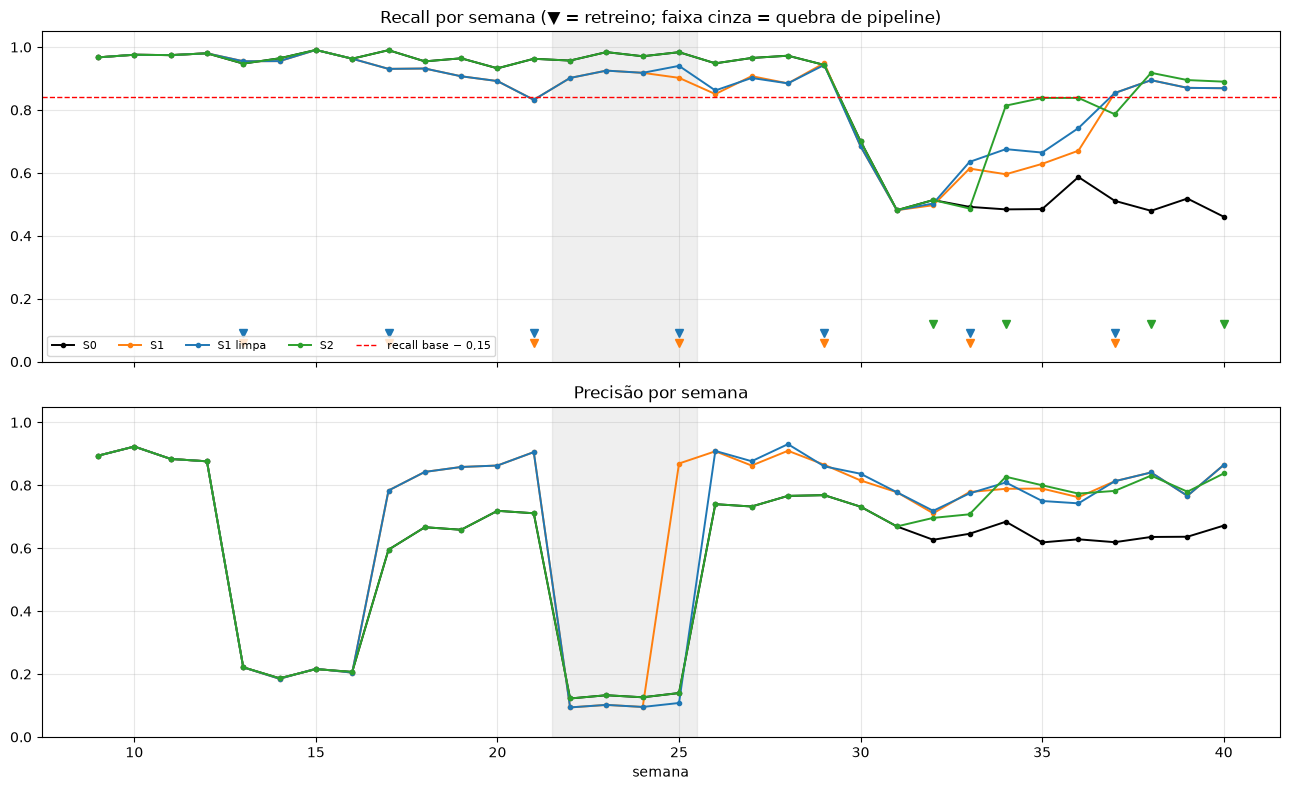

S0              S1          S1 limpa              S2         
       recall precisao recall precisao   recall precisao recall precisao
semana                                                                  
24      0.971    0.126  0.918    0.095    0.918    0.095  0.971    0.126
25      0.984    0.140  0.902    0.869    0.940    0.108  0.984    0.140
26      0.948    0.740  0.851    0.908    0.862    0.909  0.948    0.740
27      0.965    0.732  0.908    0.863    0.902    0.876  0.965    0.732
28      0.973    0.766  0.885    0.910    0.885    0.931  0.973    0.766
29      0.943    0.769  0.949    0.865    0.943    0.860  0.943    0.769
30      0.701    0.732  0.684    0.815    0.684    0.837  0.701    0.732
31      0.481    0.669  0.481    0.778    0.481    0.778  0.481    0.669
32      0.514    0.627  0.497    0.711    0.503    0.719  0.514    0.696
33      0.492    0.646  0.614    0.779    0.635    0.774  0.487    0.708
34      0.484    0.684  0.596    0.789    0.676    0.809  0.814    0.827
35      0.485    0.618  0.629    0.789    0.665    0.750  0.838    0.800
36      0.587    0.628  0.671    0.762    0.743    0.743  0.838    0.773
37      0.511    0.619  0.854    0.813    0.854    0.813  0.787    0.782
38      0.480    0.636  0.895    0.841    0.895    0.841  0.918    0.831
39      0.519    0.636  0.870    0.766    0.870    0.766  0.895    0.780
40      0.461    0.672  0.869    0.865    0.869    0.865  0.890    0.837

In [24]:
cores = {"S0": "black", "S1": "tab:orange", "S1 limpa": "tab:blue", "S2": "tab:green"}
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for nome, r in res.items():
    ax[0].plot(r.index, r.recall, "o-", ms=3, lw=1.4, color=cores[nome], label=nome)
    ax[1].plot(r.index, r.precisao, "o-", ms=3, lw=1.4, color=cores[nome], label=nome)
    for t in estrategias[nome][0]:
        ax[0].plot(t, 0.03 + 0.03 * list(cores).index(nome), "v", color=cores[nome], ms=6)
for a in ax:
    a.axvspan(21.5, 25.5, color="grey", alpha=0.12); a.grid(alpha=0.3); a.set_ylim(0, 1.05)
ax[0].axhline(LIM_REC, color="red", ls="--", lw=1, label="recall base − 0,15")
ax[0].set_title("Recall por semana (▼ = retreino; faixa cinza = quebra de pipeline)")
ax[1].set_title("Precisão por semana"); ax[1].set_xlabel("semana")
ax[0].legend(ncol=5, fontsize=8, loc="lower left"); fig.tight_layout(); plt.show()

display(pd.concat({n: r[["recall", "precisao"]] for n, r in res.items()}, axis=1).loc[24:40].round(3))

### e.1 Leitura e recomendação

| | precisão 26–29 | precisão 30–40 | recall 30–40 | retreinos |
|---|---|---|---|---|
| S0 | 0,752 | 0,652 | 0,519 | 0 |
| S1 | 0,886 | 0,792 | 0,696 | 7 |
| S1 limpa | 0,894 | 0,790 | 0,716 | 7 |
| S2 | 0,752 | 0,767 | **0,742** | **4** |

**O atraso do rótulo manda no resultado.** A campanha nova começa na semana 30, mas o rótulo da semana 30 só existe no início da 33. Nenhum retreino antes da semana 33 pode aprender o ataque novo.
- A **S2** dispara na semana 32 (reportes da 31), mas a janela 26–29 não tem nenhum exemplo da campanha: o recall continua ~0,49. No retreino da semana 34 (janela 26–31, já com 2 semanas de campanha), o recall sobe para **0,81** e depois fica entre 0,79 e 0,92.
- A **S1**, de calendário fixo, retreina na 33 com só uma semana de campanha (recall ~0,61–0,68) e só recupera de fato na **37** (0,85–0,90). Ela perde ~3 semanas com metade do phishing passando porque o calendário não sabe que algo aconteceu.
- Resultado: a S2 tem o **melhor recall em 30–40 (0,742)** com **4 retreinos em vez de 7**.

**S1 × S1 limpa.** As duas diferem só nos retreinos que pegam as semanas 22–25. Na semana 25 a S1 (treinada com a 22) parece ótima: precisão 0,87 contra 0,11. Mas isso acontece porque o modelo **aprendeu o defeito**: metade dos e-mails da semana 22 tinha idade 0 com prevalência normal, e o modelo concluiu que "idade 0 = legítimo". É o risco da seção 2.4. Quando o WHOIS for consertado o ganho desaparece, e o modelo fica com uma regra explorável: um atacante que faça a consulta WHOIS falhar ganha cara de legítimo. A S1 limpa chega a um recall melhor em 30–40 (0,716 contra 0,696) com a mesma precisão (0,790 contra 0,792) e sem essa regra espúria. Entre as duas, **a S1 limpa é a correta**.

**O ponto cego da S2.** O gatilho só olha os reportes, ou seja, phishing que passa. Ele não reage a falso positivo: nas semanas 13–29, quando a quarentena e as liberações estavam altas, a S2 nunca retreina, e a precisão em 26–29 fica igual à do modelo estático (0,752, contra 0,89 da S1). Para os 3.000 funcionários, isso é ~1 em cada 4 e-mails da quarentena sendo legítimo. Em contrapartida, os retreinos da S1 depois do drift das semanas 13–16 trocam um pouco de recall por precisão: nas semanas 17–29 a precisão sobe de ~0,6–0,7 para ~0,8–0,9, mas o recall cai de ~0,95 para 0,83–0,93. Retreinar também muda o ponto de operação do limiar fixo de 0,30.

**Recomendação: retreino por gatilho (S2), sempre sem semanas de pipeline quebrado, com dois ajustes.**
1. **Custo do erro.** O phishing perdido aqui é fraude de pagamento (item d), cujo custo é muito maior que um e-mail legítimo retido na quarentena. O recall pesa mais, e a S2 é a que melhor protege o recall no período crítico.
2. **Trabalho de rotulagem e validação.** Cada retreino exige janela verificada pelo SOC e uma validação antes de entrar em produção (portão, item f). A S2 faz 4 retreinos contra 7, todos motivados por um sinal.
3. **Ajustes.** (a) Acrescentar ao gatilho a **quarentena acima da faixa**, que cobre o lado da precisão que a S2 ignora. Esse sinal teria disparado já na semana 14, mas como a quarentena fica fora da faixa quase o tempo todo até a semana 30, ele precisa de uma regra de rearme: recalcular a faixa com as semanas seguintes a cada retreino, para não virar um retreino a cada duas semanas. E o gatilho só vale depois da checagem de qualidade do item b), já que nas semanas 22–25 a quarentena subiu por causa do pipeline, não do mundo. (b) Quando o gatilho disparar, **priorizar a rotulagem das semanas suspeitas** pelo SOC, porque o gargalo é o rótulo, não o retreino. O calendário fixo vira só uma rede de segurança (ex.: retreino a cada 8 semanas se nenhum gatilho disparar).

O gatilho por reporte depende de os reportes serem confiáveis. O item f) mostra que o feedback dos usuários pode ser manipulado, por isso todo modelo novo passa por um portão.

---
## f) Feedback, envenenamento e portão

**S3** (proposta do time): retreinar toda semana com o `rotulo_pipeline`, que não tem atraso. A partir da semana 17, o modelo da semana *t* é treinado nas semanas **t − 8 a t − 1** da produção com o `rotulo_pipeline`.

### f.1 Candidatos da S3: recall e precisão no ouro e recall real na semana de uso

In [25]:
REC_OURO_PROD = recall_score(ouro.rotulo, pontuar(modelo, ouro))
PREC_OURO_PROD = precision_score(ouro.rotulo, pontuar(modelo, ouro))
print(f"Ouro: {len(ouro)} e-mails ({ouro.rotulo.sum()} phishing).  Modelo de produção no ouro: "
      f"recall = {REC_OURO_PROD:.4f}, precisão = {PREC_OURO_PROD:.4f}")

cand, linhas_f = {}, []
for t in range(17, 41):
    d = prod[prod.semana.between(t - 8, t - 1)]
    cand[t] = novo_modelo().fit(d[FEATURES].values, d.rotulo_pipeline.values)
    po, pw = pontuar(cand[t], ouro), pontuar(cand[t], grupos[t])
    linhas_f.append({"semana": t,
                     "recall_ouro": recall_score(ouro.rotulo, po),
                     "precisao_ouro": precision_score(ouro.rotulo, po),
                     "recall_real_semana": recall_score(grupos[t].rotulo, pw),
                     "precisao_real_semana": precision_score(grupos[t].rotulo, pw),
                     "frac_phishing_rotulado_1_no_treino": d[d.rotulo == 1].rotulo_pipeline.mean()})
s3 = pd.DataFrame(linhas_f).set_index("semana")
s3.round(3)

Ouro: 2928 e-mails (928 phishing).  Modelo de produção no ouro: recall = 0.9892, precisão = 0.9903


,recall_ouro,precisao_ouro,recall_real_semana,precisao_real_semana,frac_phishing_rotulado_1_no_treino
semana,,,,,
17,0.976,0.984,0.990,0.571,0.948
18,0.976,0.984,0.970,0.643,0.948
19,0.975,0.985,0.957,0.632,0.933
20,0.971,0.984,0.953,0.701,0.912
21,0.971,0.984,0.969,0.693,0.882
22,0.969,0.986,0.969,0.108,0.854
23,0.966,0.989,0.979,0.135,0.817
24,0.964,0.988,0.971,0.127,0.773
25,0.968,0.986,0.978,0.140,0.738


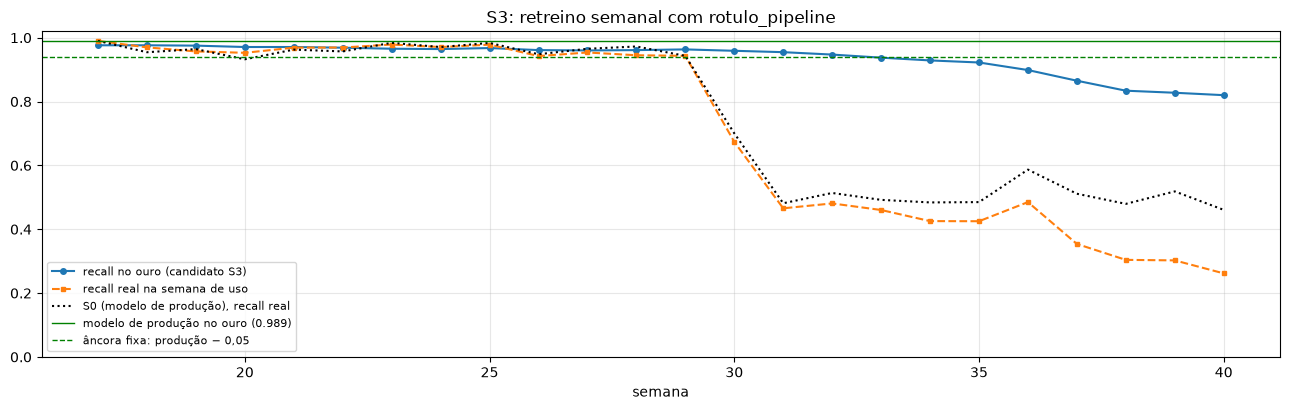

Queda do recall no ouro de uma semana para a outra: média 0.0068, máxima 0.0334; total 0.976 → 0.820


In [26]:
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(s3.index, s3.recall_ouro, "o-", ms=4, label="recall no ouro (candidato S3)")
ax.plot(s3.index, s3.recall_real_semana, "s--", ms=3.5, label="recall real na semana de uso")
ax.plot(desemp.loc[17:].index, desemp.loc[17:, "recall"], ":", color="black", label="S0 (modelo de produção), recall real")
ax.axhline(REC_OURO_PROD, color="green", lw=1, label=f"modelo de produção no ouro ({REC_OURO_PROD:.3f})")
ax.axhline(REC_OURO_PROD - 0.05, color="green", ls="--", lw=1, label="âncora fixa: produção − 0,05")
ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.set_xlabel("semana"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("S3: retreino semanal com rotulo_pipeline")
fig.tight_layout(); plt.show()
print("Queda do recall no ouro de uma semana para a outra: "
      f"média {-s3.recall_ouro.diff().mean():.4f}, máxima {-s3.recall_ouro.diff().min():.4f}; "
      f"total {s3.recall_ouro.iloc[0]:.3f} → {s3.recall_ouro.iloc[-1]:.3f}")

### f.2 Portões: relativo × âncora fixa

- **Relativo:** o candidato só substitui o modelo atual se o recall no ouro não cair mais de 0,05 em relação ao **modelo atual**.
- **Âncora fixa:** o candidato não pode ficar mais de 0,05 abaixo do recall no ouro do **modelo de produção** (fixo).

Quando o candidato é bloqueado, continua valendo o último modelo aceito (no início, o de produção).

In [27]:
def portao(tipo):
    atual, rec_atual, nome_atual, log = modelo, REC_OURO_PROD, "produção", []
    for t in range(17, 41):
        r = s3.recall_ouro[t]
        limite = (rec_atual if tipo == "relativo" else REC_OURO_PROD) - 0.05
        aceito = r >= limite - 1e-12
        if aceito:
            atual, rec_atual, nome_atual = cand[t], r, f"cand. {t}"
        pw = pontuar(atual, grupos[t])
        log.append({"semana": t, "recall_ouro_cand": r, "limite": limite,
                    "decisao": "passa" if aceito else "BLOQUEADO", "modelo_em_uso": nome_atual,
                    "recall_ouro_em_uso": rec_atual,
                    "recall_real": recall_score(grupos[t].rotulo, pw),
                    "precisao_real": precision_score(grupos[t].rotulo, pw)})
    return pd.DataFrame(log).set_index("semana")

g_rel, g_anc = portao("relativo"), portao("ancora")
display(pd.concat({"relativo": g_rel[["limite", "decisao", "modelo_em_uso", "recall_ouro_em_uso", "recall_real"]],
                   "âncora fixa": g_anc[["limite", "decisao", "modelo_em_uso", "recall_ouro_em_uso", "recall_real"]]},
                  axis=1).round(3))

for nome, g in [("relativo", g_rel), ("âncora fixa", g_anc)]:
    bloq = list(g.index[g.decisao == "BLOQUEADO"])
    print(f"Portão {nome}: bloqueia nas semanas {periodos(pd.Series(True, index=bloq)) if bloq else 'nenhuma'}")
prim = g_anc.index[g_anc.decisao == "BLOQUEADO"][0]
print(f"Primeiro bloqueio da âncora: semana {prim}, recall no ouro do candidato = {s3.recall_ouro[prim]:.4f} "
      f"< limite {REC_OURO_PROD - 0.05:.4f}")

resumo_f = pd.DataFrame({
    "S0 (sem retreino)": [desemp.loc[30:40, "recall"].mean(), desemp.loc[30:40, "precisao"].mean(), REC_OURO_PROD],
    "S3 sem portão": [s3.loc[30:40, "recall_real_semana"].mean(), s3.loc[30:40, "precisao_real_semana"].mean(), s3.recall_ouro[40]],
    "S3 + portão relativo": [g_rel.loc[30:40, "recall_real"].mean(), g_rel.loc[30:40, "precisao_real"].mean(), g_rel.recall_ouro_em_uso[40]],
    "S3 + âncora fixa": [g_anc.loc[30:40, "recall_real"].mean(), g_anc.loc[30:40, "precisao_real"].mean(), g_anc.recall_ouro_em_uso[40]],
    "S2 (rótulo verificado, item e)": [res["S2"].loc[30:40, "recall"].mean(), res["S2"].loc[30:40, "precisao"].mean(), np.nan],
}, index=["recall médio real 30–40", "precisão média real 30–40", "recall no ouro do modelo em uso na sem. 40"]).T
resumo_f.round(3)

relativo                                                      âncora fixa                                                        
         limite decisao modelo_em_uso recall_ouro_em_uso recall_real      limite    decisao modelo_em_uso recall_ouro_em_uso recall_real
semana                                                                                                                                  
17        0.939   passa      cand. 17              0.976       0.990       0.939      passa      cand. 17              0.976       0.990
18        0.926   passa      cand. 18              0.976       0.970       0.939      passa      cand. 18              0.976       0.970
19        0.926   passa      cand. 19              0.975       0.957       0.939      passa      cand. 19              0.975       0.957
20        0.925   passa      cand. 20              0.971       0.953       0.939      passa      cand. 20              0.971       0.953
21        0.921   passa      cand. 21              0.971       0.969       0.939      passa      cand. 21              0.971       0.969
22        0.921   passa      cand. 22              0.969       0.969       0.939      passa      cand. 22              0.969       0.969
23        0.919   passa      cand. 23              0.966       0.979       0.939      passa      cand. 23              0.966       0.979
24        0.916   passa      cand. 24              0.964       0.971       0.939      passa      cand. 24              0.964       0.971
25        0.914   passa      cand. 25              0.968       0.978       0.939      passa      cand. 25              0.968       0.978
26        0.918   passa      cand. 26              0.961       0.943       0.939      passa      cand. 26              0.961       0.943
27        0.911   passa      cand. 27              0.960       0.954       0.939      passa      cand. 27              0.960       0.954
28        0.910   passa      cand. 28              0.961       0.945       0.939      passa      cand. 28              0.961       0.945
29        0.911   passa      cand. 29              0.963       0.943       0.939      passa      cand. 29              0.963       0.943
30        0.913   passa      cand. 30              0.959       0.674       0.939      passa      cand. 30              0.959       0.674
31        0.909   passa      cand. 31              0.955       0.466       0.939      passa      cand. 31              0.955       0.466
32        0.905   passa      cand. 32              0.947       0.481       0.939      passa      cand. 32              0.947       0.481
33        0.897   passa      cand. 33              0.938       0.460       0.939  BLOQUEADO      cand. 32              0.947       0.444
34        0.888   passa      cand. 34              0.929       0.426       0.939  BLOQUEADO      cand. 32              0.947       0.473
35        0.879   passa      cand. 35              0.922       0.425       0.939  BLOQUEADO      cand. 32              0.947       0.461
36        0.872   passa      cand. 36              0.899       0.485       0.939  BLOQUEADO      cand. 32              0.947       0.557
37        0.849   passa      cand. 37              0.865       0.354       0.939  BLOQUEADO      cand. 32              0.947       0.478
38        0.815   passa      cand. 38              0.834       0.304       0.939  BLOQUEADO      cand. 32              0.947       0.439
39        0.784   passa      cand. 39              0.828       0.302       0.939  BLOQUEADO      cand. 32              0.947       0.475
40        0.778   passa      cand. 40              0.820       0.262       0.939  BLOQUEADO      cand. 32              0.947       0.435

Portão relativo: bloqueia nas semanas nenhuma
Portão âncora fixa: bloqueia nas semanas 33–40
Primeiro bloqueio da âncora: semana 33, recall no ouro do candidato = 0.9375 < limite 0.9392


,recall médio real 30–40,precisão média real 30–40,recall no ouro do modelo em uso na sem. 40
S0 (sem retreino),0.519,0.652,0.989
S3 sem portão,0.422,0.640,0.820
S3 + portão relativo,0.422,0.640,0.820
S3 + âncora fixa,0.489,0.663,0.947
"S2 (rótulo verificado, item e)",0.742,0.767,NaN


### f.3 De onde vêm as liberações (semanas 18 a 40)

,liberacoes,frac_phishing
destinatario,,
u2878,176,1.000
u1945,149,0.993
u1588,142,0.993
u0635,138,1.000
u1176,137,1.000
u1392,136,1.000
u2034,135,0.993
u0960,133,0.992


Liberações nas semanas 18–40: 3141, vindas de 1452 caixas (de 3000).
As 8 caixas com mais liberações: 1146 liberações = 36.5% do total (0.27% das caixas). A 9ª caixa tem 5.
Fração das liberações que era phishing de verdade: top 8 = 99.7%; demais caixas = 2.6%
Primeira semana com liberação de alguma das 8 caixas: 14 | liberações delas nas semanas 9–17: 4


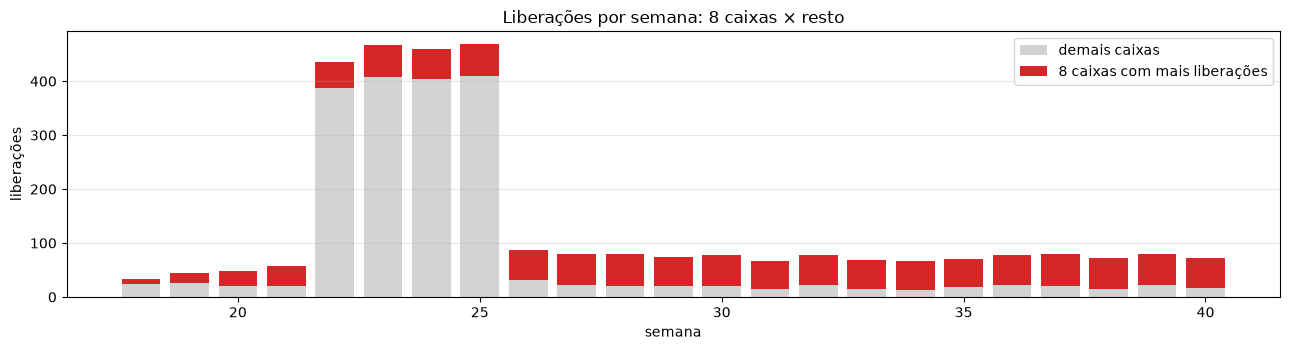

semana,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40
top 8,9,19,27,37,49,60,55,59,56,57,58,54,56,53,54,53,54,53,55,58,58,56,56
demais caixas,24,26,21,20,387,407,404,410,31,23,21,20,21,14,23,15,13,18,22,21,14,23,17
phishing liberado pelo top 8,9,19,27,37,47,60,55,58,56,57,58,54,56,53,53,53,54,53,55,58,58,56,56


In [28]:
lib = prod[(prod.feedback_usuario == -1) & prod.semana.between(18, 40)]
por_caixa = lib.groupby("destinatario").agg(liberacoes=("id_email", "size"),
                                             frac_phishing=("rotulo", "mean")).sort_values("liberacoes", ascending=False)
top8 = por_caixa.head(8)
display(top8.round(3))

caixas_total = prod.destinatario.nunique()
print(f"Liberações nas semanas 18–40: {len(lib)}, vindas de {len(por_caixa)} caixas (de {caixas_total}).")
print(f"As 8 caixas com mais liberações: {top8.liberacoes.sum()} liberações = {top8.liberacoes.sum() / len(lib):.1%} do total "
      f"({8 / caixas_total:.2%} das caixas). A 9ª caixa tem {por_caixa.liberacoes.iloc[8]}.")
lib_top = lib[lib.destinatario.isin(top8.index)]; lib_out = lib[~lib.destinatario.isin(top8.index)]
print(f"Fração das liberações que era phishing de verdade: top 8 = {lib_top.rotulo.mean():.1%}; "
      f"demais caixas = {lib_out.rotulo.mean():.1%}")

sem_top = pd.DataFrame({"top 8": lib_top.groupby("semana").size(), "demais caixas": lib_out.groupby("semana").size(),
                        "phishing liberado pelo top 8": lib_top[lib_top.rotulo == 1].groupby("semana").size()}).fillna(0).astype(int)
# quando começaram? (liberações dessas caixas desde a semana 9)
lib_all_top = prod[(prod.feedback_usuario == -1) & prod.destinatario.isin(top8.index)]
print("Primeira semana com liberação de alguma das 8 caixas:", lib_all_top.semana.min(),
      "| liberações delas nas semanas 9–17:", (lib_all_top.semana < 18).sum())

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(sem_top.index, sem_top["demais caixas"], label="demais caixas", color="lightgrey")
ax.bar(sem_top.index, sem_top["top 8"], bottom=sem_top["demais caixas"], label="8 caixas com mais liberações", color="tab:red")
ax.set_xlabel("semana"); ax.set_ylabel("liberações"); ax.legend(); ax.grid(alpha=0.3, axis="y")
ax.set_title("Liberações por semana: 8 caixas × resto")
fig.tight_layout(); plt.show()
sem_top.T

### f.4 Phishing perdido e o `rotulo_pipeline` (semanas 30 a 40)

In [29]:
perd = prod[prod.semana.between(30, 40) & (prod.rotulo == 1) & (prod.alerta == 0)]
print(f"Phishing que o modelo de produção deixou passar nas semanas 30–40: {len(perd)}")
print(f"Desses, aparecem como 1 no rotulo_pipeline (alguém reportou): {perd.rotulo_pipeline.sum()} "
      f"= {perd.rotulo_pipeline.mean():.1%}")
print(f"Entram no treino da S3 como LEGÍTIMOS: {(perd.rotulo_pipeline == 0).sum()} = {(perd.rotulo_pipeline == 0).mean():.1%}")

# qualidade do rotulo_pipeline como um todo, por período
qual_pipe = prod.groupby(pd.cut(prod.semana, [8, 17, 29, 40], labels=["9–17", "18–29", "30–40"]), observed=True).apply(
    lambda d: pd.Series({"phishing marcado 1": d[d.rotulo == 1].rotulo_pipeline.mean(),
                         "legítimo marcado 1": d[d.rotulo == 0].rotulo_pipeline.mean(),
                         "concordância com rotulo": (d.rotulo == d.rotulo_pipeline).mean()}))
qual_pipe.round(3)

Phishing que o modelo de produção deixou passar nas semanas 30–40: 948
Desses, aparecem como 1 no rotulo_pipeline (alguém reportou): 196 = 20.7%
Entram no treino da S3 como LEGÍTIMOS: 752 = 79.3%


,phishing marcado 1,legítimo marcado 1,concordância com rotulo
semana,,,
9–17,0.946,0.048,0.952
18–29,0.677,0.097,0.890
30–40,0.307,0.013,0.947


### f.5 Leitura

**1. Candidatos da S3.** O recall no ouro cai devagar e sem parar: de **0,976** (semana 17) para **0,820** (semana 40), em média −0,007 por semana e no máximo −0,033 de uma semana para a outra. Nenhum passo isolado chama atenção. A precisão no ouro fica em ~0,99, então o modelo **não** passa a alertar demais: ele passa a deixar phishing passar. O recall real na semana de uso é pior que o do modelo estático a partir da semana 30 (0,26–0,49 contra 0,46–0,59). Na semana 40, a S3 pega **26%** do phishing, contra 46% do modelo que nunca foi retreinado. Retreinar com o rótulo do pipeline deixou o detector **pior que não retreinar**.

**2. Portões.**
- **Portão relativo: não bloqueia nenhuma semana.** Cada candidato perde no máximo 0,033 em relação ao anterior, abaixo da tolerância de 0,05, e o limite desce junto: 0,939 → 0,778. O modelo em uso termina com recall de 0,820 no ouro, 0,17 abaixo do original. Recall médio real nas semanas 30–40: **0,422**.
- **Âncora fixa: bloqueia nas semanas 33 a 40.** O candidato 33 tem 0,938 no ouro, contra um limite fixo de 0,989 − 0,05 = 0,939. O modelo em uso fica congelado no candidato 32 (0,947 no ouro). Recall médio real nas semanas 30–40: **0,489**.
- A âncora fixa faz o que promete: impede o modelo de **esquecer** o phishing que já conhecia. Mas não o faz **aprender** a campanha nova, que nem está no ouro (o ouro é congelado da referência, seção 2.12). Mesmo com o portão, a S3 fica abaixo do modelo estático (0,519) e muito abaixo da S2 com rótulo verificado (0,742). O portão protege o retreino, mas não substitui o monitoramento nem o rótulo bom.

**3. Concentração das liberações.** Das 3.141 liberações das semanas 18–40, **1.146 (36,5%) vêm de 8 caixas**, 0,27% das 3.000. Essas 8 têm de 133 a 176 liberações cada; a 9ª caixa tem 5. E **99,7%** do que essas 8 caixas liberaram era phishing verificado, contra 2,6% nas demais. O volume delas cresce aos poucos: 9, 19, 27, 37, 49 e 60 liberações por semana entre as semanas 18 e 23, depois fica estável em ~55 por semana. Antes da semana 18 elas quase não liberavam (4 liberações). Os dois rastros da seção 2.11 estão presentes: **concentração** (poucas origens com volume anormal) e **direção do erro** (liberam justamente phishing). Isso não é usuário corrigindo falso positivo; é **envenenamento pelo canal de feedback** (MITRE ATLAS AML.T0020), como as campanhas de "não é spam" contra o Gmail em 2017–2018.

**4. Cegueira do rótulo do pipeline.** Dos **948** phishing que o modelo deixou passar nas semanas 30–40, só **196 (20,7%)** foram reportados e aparecem como 1 no `rotulo_pipeline`. Os outros **79,3%** entram no treino da S3 **como legítimos**. Dentro do phishing, a fração marcada como 1 no `rotulo_pipeline` cai de 0,95 nas semanas 9–17 para 0,68 nas 18–29 e 0,31 nas 30–40. A **concordância** geral com o rótulo verificado continua alta (0,89–0,95), porque o legítimo domina o tráfego: olhar a acurácia do rótulo não revela o problema.

**Conclusão: o retreino automático com `rotulo_pipeline` não deve ser ligado.** Ele junta os dois riscos da seção 2.10 com um ataque ativo:
- **Cegueira:** o phishing que passa sem ser reportado entra como legítimo, e o retreino confirma o erro.
- **Ciclo de realimentação:** o rótulo nasce da decisão do próprio modelo. Cada retreino que deixa passar mais phishing gera mais rótulos "legítimo" para o próximo.
- **Sapo na panela:** as 8 caixas aumentaram as liberações aos poucos e depois as mantiveram. Com retreino semanal, cada rodada absorve um pouco de veneno e nenhum passo isolado passa de 0,05. O portão relativo, que compara com o modelo anterior, é exatamente o que esse ataque contorna: a régua desce junto com o modelo.

**Condições para ligar algum retreino automático:**
1. Treinar com o **rótulo verificado pelo SOC** (respeitando t − 3), não com o `rotulo_pipeline`. O feedback serve como sinal de monitoramento e para priorizar o que o SOC verifica.
2. Se o feedback entrar no treino, **limitar o peso por origem**: nenhuma caixa pode responder por mais que uma fração pequena das liberações da janela. Caixas com volume anormal vão para investigação, e as liberações delas saem do treino.
3. Usar um **portão de âncora fixa** no conjunto de ouro (nunca só relativo), mais a comparação com o modelo atual no mesmo tráfego recente rotulado. Atualizar o ouro pelo SOC com ataques novos verificados (ex.: a fraude de pagamento das semanas 30+), para que ele também meça aprendizado e não só esquecimento.
4. Excluir da janela as semanas com falha de qualidade (item b).
5. Exigir **aprovação humana** antes de promover um modelo bloqueado ou de mudar o ouro.

---
## g) Plano de monitoramento e automação

### g.1 Replay: o que cada sinal do plano teria acusado nas semanas 9–40

Antes de fixar os limiares, cada sinal é rodado sobre o histórico. Para sinais com rótulo, a coluna "conhecido em" aplica o atraso de t − 3.

In [30]:
def semanas_onde(mask):
    mask = mask.reindex(semanas).fillna(False).astype(bool)
    return periodos(mask), (int(mask.idxmax()) if mask.any() else None)

replay = []
def add(sinal, mask, atraso=1):
    '''atraso: 1 = dado da semana conhecido no fim dela (início da seguinte); 3 = rótulo (t − 3);
    0 = decidido no início da própria semana (portão de retreino).'''
    per, prim = semanas_onde(mask)
    replay.append({"sinal": sinal, "semanas com alarme": per, "1º alarme (semana do dado)": prim,
                   "conhecido em (início da semana)": (prim + atraso) if prim else None})

# 1. qualidade dos dados
add("1. Qualidade: fora de [mín,máx] > 1% ou Δzeros > 0,20 (alguma feature)",
    ((qualidade["fora_faixa"] > 0.01) | ((qualidade["zeros"] - ref_q.zeros_ref).abs() > 0.20)).any(axis=1))
# 2. drift de dados
add("2a. Drift: PSI ≥ 0,10 em alguma feature (atenção)", (PSI[FEATURES] >= 0.10).any(axis=1))
add("2b. Drift: PSI ≥ 0,25 em alguma feature (ação)", (PSI[FEATURES] >= 0.25).any(axis=1))
# 3. saída do modelo
add("3. Saída: fração em quarentena fora da faixa normal",
    (painel.quarentena > faixa.loc["quarentena", "sup"]) | (painel.quarentena < faixa.loc["quarentena", "inf"]))
# 4. usuários: reportes
add("4. Usuários: reportes > limite superior da faixa", painel.reportes > faixa.loc["reportes", "sup"])
# 5. concentração do feedback
lib_sem_caixa = prod[prod.feedback_usuario == -1].groupby(["semana", "destinatario"]).size()
caixas_3mais = lib_sem_caixa.groupby("semana").apply(lambda s: (s >= 3).sum()).reindex(semanas, fill_value=0)
add("5. Feedback: ≥ 3 caixas com ≥ 3 liberações na semana", caixas_3mais >= 3)
# 6. desempenho com rótulo (t − 3)
add("6a. Rótulo: recall < base − 0,15", desemp.recall < LIM_REC, atraso=3)
add("6b. Rótulo: precisão < base − 0,10", desemp.precisao < PREC_BASE - 0.10, atraso=3)
ph_mask = pd.Series(False, index=semanas); ph_mask[sem_ph] = True
add("6c. Rótulo: Page-Hinkley (δ = 0,05, λ = 8) no fluxo de erros", ph_mask, atraso=3)
# 7. integridade do retreino: candidato S3 abaixo da âncora fixa no ouro
add("7. Retreino: candidato com recall no ouro < âncora (0,989 − 0,05)",
    s3.recall_ouro < REC_OURO_PROD - 0.05, atraso=0)
# 8. fidelidade do rótulo automático
fid = prod[prod.rotulo == 1].groupby("semana").rotulo_pipeline.mean()
add("8. Rótulo do pipeline: phishing verificado marcado 1 < 0,80", fid < 0.80, atraso=3)

print("Caixas com ≥ 3 liberações por semana:", caixas_3mais.loc[9:21].to_dict())
pd.DataFrame(replay).set_index("sinal")

Caixas com ≥ 3 liberações por semana: {9: 0, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 1, 19: 4, 20: 6, 21: 7}


,semanas com alarme,1º alarme (semana do dado),conhecido em (início da semana)
sinal,,,
"1. Qualidade: fora de [mín,máx] > 1% ou Δzeros > 0,20 (alguma feature)",22–25,22,23
"2a. Drift: PSI ≥ 0,10 em alguma feature (atenção)","13–16, 22–25",13,14
"2b. Drift: PSI ≥ 0,25 em alguma feature (ação)",22–25,22,23
3. Saída: fração em quarentena fora da faixa normal,"13–30, 32–33, 36",13,14
4. Usuários: reportes > limite superior da faixa,"31–34, 37–40",31,32
5. Feedback: ≥ 3 caixas com ≥ 3 liberações na semana,19–40,19,20
"6a. Rótulo: recall < base − 0,15",30–40,30,33
"6b. Rótulo: precisão < base − 0,10",13–40,13,16
"6c. Rótulo: Page-Hinkley (δ = 0,05, λ = 8) no fluxo de erros",30,30,33


O replay confirma que cada incidente tem um sinal que o acusa, e que os sinais **sem rótulo** chegam antes:

| Evento | Primeiro sinal | Quando se sabe |
|---|---|---|
| Drift de dados 13–16 | quarentena (3) e PSI ≥ 0,10 (2a) | início da 14 |
| Envenenamento pelo feedback (desde 18) | concentração (5), na semana 19 | início da 20 — **13 semanas antes** do rótulo mostrar queda de recall |
| Quebra do WHOIS 22–25 | qualidade (1) e PSI ≥ 0,25 (2b) | início da 23 |
| Drift de conceito (BEC) desde 30 | reportes (4), na semana 31 | início da 32; o rótulo confirma na 33 |
| S3 esquecendo o phishing conhecido | portão de âncora (7) | no momento do retreino da 33 |

### g.2 Plano de monitoramento

| # | Sinal | Como medir | Limiar de alarme | Quem é acionado | Primeira ação |
|---|---|---|---|---|---|
| 1 | **Qualidade dos dados** (por feature) | Por feature e por dia/semana: fração de nulos, de zeros, nº de valores distintos e fração fora de [mín, máx] da referência | Fora da faixa > 1% das linhas, ou fração de zeros/nulos variando > 0,20, ou distintos < 60% da referência | Engenharia de dados / time do gateway | Checar o extrator (ex.: WHOIS); tratar valor inválido como ausente e imputar ou usar regra de contingência; marcar as semanas afetadas como **"fora do treino"** |
| 2 | **Drift de dados** (P(X)) | PSI por feature e do `score` × referência (função da seção 5), semanal; KS só como contexto | PSI ≥ 0,10: atenção; ≥ 0,25: ação. Sempre depois de descartar o sinal 1 | Dono do modelo (ML) | Ver qual segmento mudou e o efeito na quarentena (sinal 3); pedir ao SOC uma amostra rotulada do tráfego novo; avaliar retreino com rótulo verificado |
| 3 | **Saída do modelo** | Fração em quarentena e score médio, diário e semanal | Fora da faixa normal (média ± 3 desvios amostrais das semanas de base; refazer a base após cada troca de modelo) | Plantão do SOC + dono do modelo | Cruzar com os sinais 1, 2 e 4: quarentena e liberações subindo juntas indicam falso positivo; quarentena parada com reportes subindo indica phishing passando. Amostrar a quarentena |
| 4 | **Usuários: reportes** (phishing entregue) | Nº de reportes (`feedback = +1`) por semana; conteúdo dos reportados | Acima do limite superior da faixa normal (~19,6/semana) | SOC (resposta a incidente) | Triagem dos reportados para achar a campanha; priorizar a rotulagem das últimas semanas; regra temporária (ex.: banner/quarentena para pedido de pagamento de remetente externo) |
| 5 | **Usuários: concentração das liberações** | Liberações (`feedback = −1`) por caixa e semana; participação das caixas mais ativas | ≥ 3 caixas com ≥ 3 liberações na mesma semana (base 9–17: nenhuma caixa com 3) | Segurança / SOC (investigar contas) + dono do modelo | Tirar o feedback dessas caixas de qualquer treino; verificar com o SOC o que elas liberaram; investigar comprometimento ou insider; revogar a autoliberação delas |
| 6 | **Desempenho com rótulo** | Precisão e recall semanais com o `rotulo` (tabela t − 3); Page-Hinkley (δ = 0,05, λ = 8) no fluxo de phishing perdido | Recall < base − 0,15 (0,841), precisão < base − 0,10 (0,81), ou disparo do Page-Hinkley | Dono do modelo + gestor do SOC | Analisar os falsos negativos/positivos da semana; disparar retreino com rótulo verificado (S2), com janela sem semanas marcadas pelo sinal 1 |
| 7 | **Integridade do retreino** (portão) | Para cada candidato: recall e precisão no **ouro** × âncora fixa; comparação com o modelo atual nas últimas semanas rotuladas; origem dos rótulos da janela | Recall no ouro < 0,989 − 0,05; precisão no ouro < 0,94; pior que o modelo atual no tráfego recente; janela com semana marcada no sinal 1 ou com feedback de caixas do sinal 5 | Dono do modelo + aprovador humano | Bloquear a promoção e manter o modelo atual; revisar a janela de treino |
| 8 | **Fidelidade do rótulo automático** | Entre os phishing verificados (t − 3), fração com `rotulo_pipeline = 1` | < 0,80 | Dono do modelo | Proibir o uso do `rotulo_pipeline` no treino; tratá-lo só como sinal de monitoramento |

### g.3 Relação com MITRE ATLAS e NIST AI RMF

- **AML.T0020 – Training Data Poisoning.** O retreino automático com feedback é exatamente o canal desta técnica ("manipular processos de feedback e de coleta de dados"). Os sinais **5** (concentração e direção do erro), **7** (portão) e **8** (fidelidade do rótulo) são as defesas, e a regra de não treinar com `rotulo_pipeline` fecha o canal. O item f) mostrou o ataque na prática: 8 caixas liberando phishing de forma gradual.
- **AML.T0031 – Erode AI Model Integrity.** O sapo na panela degrada o modelo aos poucos (recall no ouro de 0,976 a 0,820 sem nenhum salto). Por isso o portão do sinal **7** compara com uma **âncora fixa**, não com o modelo anterior.
- **AML.M0008 – Validate AI Model.** O sinal **7** é essa mitigação: validar todo candidato contra uma linha de base confiável (ouro congelado + modelo aprovado) e investigar regressões. Os sinais **2, 3 e 6** são a validação contínua em operação. Seguindo o ATLAS, drift e envenenamento são investigados juntos: todo alarme de 2/3/4 olha também o sinal 5.
- **NIST AI RMF MEASURE 2.4** (funcionalidade e comportamento monitorados em produção): sinais **1 a 6 e 8**, com limiar e frequência definidos.
- **NIST AI RMF MANAGE 4.1** (plano pós-implantação com captação da contribuição dos usuários, contestação, resposta a incidentes, recuperação e gestão de mudanças): os sinais **4 e 5** captam e auditam o feedback dos usuários; a coluna "quem é acionado" e a "primeira ação" formam o roteiro de resposta; o rollback para o último modelo aprovado é a recuperação; e o portão + aprovação humana (sinal **7**) é a gestão de mudanças.

### g.4 Automação: o que pode rodar sozinho

O pipeline pode fazer **sem aprovação** tudo o que é observação ou reversível. Isso inclui: calcular todos os sinais e abrir os alarmes; marcar semanas com falha de qualidade como "fora do treino"; treinar candidatos **só com o rótulo verificado pelo SOC** (janela t − 10 a t − 3, sem semanas marcadas e sem feedback de caixas sinalizadas); avaliar cada candidato no ouro e no tráfego recente; e voltar (rollback) para o último modelo aprovado se um sinal de desempenho disparar. **Precisam passar pelo portão e por uma pessoa** todas as mudanças no que o modelo aprende ou no que conta como verdade:
- **promover** um candidato para produção (portão de âncora fixa no ouro + não ser pior que o modelo atual nas últimas semanas rotuladas + aprovação do dono do modelo);
- **mudar** o limiar, a âncora ou o conjunto de ouro (que só cresce com exemplos verificados pelo SOC, como os ataques de fraude de pagamento, e nunca é tocado pelo retreino);
- **incluir** qualquer rótulo que não seja o verificado (feedback, `rotulo_pipeline`) ou uma semana marcada no treino.

Esse desenho impede o **envenenamento gradual pelo feedback** (sapo na panela, AML.T0020/AML.T0031) que o item f) encontrou. As liberações das 8 caixas não viram rótulo de treino, porque o treino usa o rótulo verificado. Mesmo que virassem, o sinal 5 dispara na semana 19, e o portão de âncora fixa não desce junto com o modelo, de modo que uma degradação lenta acaba bloqueada. E nenhum modelo entra em produção sem uma pessoa olhar a evidência. O mesmo desenho também impede que o modelo aprenda o defeito do pipeline como padrão (item b/e).